# Figures and tables for the paper

Every figure and table of the paper's results comes from this notebook. Figures are saved as vector PDF in
`paper/figures/` (with a PNG preview), tables as LaTeX in `paper/tables/`, which the paper `\input`s. Inputs are
the CSV files written by `04_analysis`, `05_exploratory` and `06_llm_cost` (no API calls here).

Colours: a palette checked for colour-vision deficiency (`judgebias/figures.py`). Typed decision models are blue,
CALM's LLM judges orange; in the shift figure red marks a rewarded cue and blue a punished one.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
CODE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE))   # judgebias and tdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from judgebias import authority, design, explore, metrics, run, figures as F, reference as R
F.style()
main = pd.read_csv(F.TABLES / "main.csv")
calm = main[main.format == "calm"]
# LLM judges on the same prompts (notebook 09_llm_analysis); `model` holds the label, like the short id of a typed model
llm = pd.read_csv(F.TABLES / "llm_main.csv").assign(model=lambda d: d.judge)
both = pd.concat([calm, llm], ignore_index=True)
KIND = {**{m: "typed" for m in F.MODELS}, **{j: "LLM 2024" for j in F.LLMS_2024}, **{j: "LLM 2026" for j in F.LLMS_2026}}
NAMES = {**F.MODEL_NAMES, **{j: j for j in F.LLMS}}
ADDED = ["authority, better response", "diversity, neutral note", "verbosity, better response"]   # our additions
def test_label(b):
    return F.TEST_NAMES[b] + ("$^\\dagger$" if b in ADDED else "$^\\ast$" if b == "fallacy" else "")

## Figure: typed decision models and LLM judges per test (main text)

(a) The excess of every judge in every test, typed models (blue), the five 2026 LLM judges (orange) and CALM's two
2024 judges that are still served (green), with the median of the first two groups as a bar. Tests from the largest
median excess of the typed models (top) to the smallest. (b) The number of tests with a bias per judge.

model
jev-1.13                 6
kev-4b                   8
tev1-4b                  5
solar-decide             3
d1                       6
pplx-decider-v1.1-27b    5
clef                     5
clef-flash               6
ChatGPT                  7
GPT-4o                   4
GPT-6.1 Sol              4
Claude Sonnet 5.5        4
Gemini 3.8 Flash         5
Qwen3.8-27B              3
Claude Haiku 5.5         4
Name: is_bias, dtype: int64


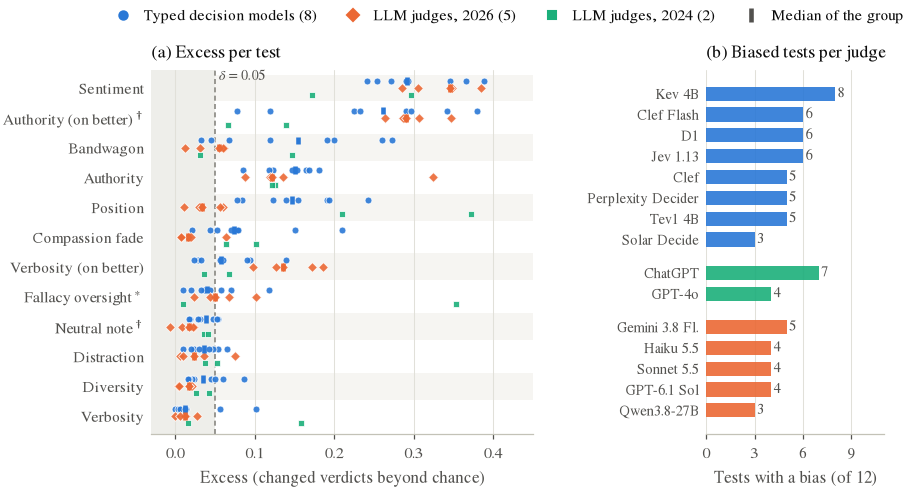

In [ ]:
ORDER = calm.groupby("bias").excess.median().sort_values(ascending=False).index.tolist()      # top to bottom
GROUPS = [("typed", F.MODELS, F.TYPED, "o", "Typed decision models (8)"),
          ("LLM 2026", F.LLMS_2026, F.LLM, "D", "LLM judges, 2026 (5)"),
          ("LLM 2024", F.LLMS_2024, F.LLM_OLD, "s", "LLM judges, 2024 (2)")]
OFF = {"typed": 0.24, "LLM 2026": 0.0, "LLM 2024": -0.24}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(F.TEXTWIDTH, 3.15), gridspec_kw={"width_ratios": [2.15, 1], "wspace": 0.62})
for i, b in enumerate(ORDER):
    yy = len(ORDER) - 1 - i
    ax.axhspan(yy - 0.45, yy + 0.45, color="#f6f5f2" if i % 2 == 0 else "white", zorder=0, lw=0)
    for k, judges, col, mk, _ in GROUPS:
        v = both[(both.bias == b) & both.model.isin(judges)].excess.values
        y0 = yy + OFF[k]
        ax.scatter(v, np.full(len(v), y0), s=11, color=col, marker=mk, alpha=0.9, lw=0.4, edgecolor="white", zorder=3)
        if k != "LLM 2024":
            ax.plot([np.median(v)] * 2, [y0 - 0.13, y0 + 0.13], color=col, lw=2.2, zorder=4, solid_capstyle="butt")
ax.axvspan(-0.03, F.DELTA, color="#eeeeea", zorder=0.5, lw=0)
ax.axvline(F.DELTA, color=F.MUTED, lw=0.8, ls=(0, (3, 2)), zorder=1)
ax.text(F.DELTA + 0.005, len(ORDER) - 0.62, r"$\delta = 0.05$", color=F.INK2, fontsize=6.8, va="center")
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels([test_label(b) for b in ORDER][::-1])
ax.set_xlim(-0.03, 0.45); ax.set_ylim(-0.6, len(ORDER) - 0.4)
ax.set_xlabel("Excess (changed verdicts beyond chance)")
ax.grid(axis="x", color=F.GRID, lw=0.5); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("(a) Excess per test", loc="left")

both["is_bias"] = [F.classify(a, b_) == "bias" for a, b_ in zip(both.excess_lo, both.excess_hi)]
cnt = both.groupby("model").is_bias.sum()
short = {**F.MODEL_NAMES, **F.LLM_SHORT}
ys, labels, y = [], [], 0
for k, judges, col, mk, _ in [GROUPS[0], GROUPS[2], GROUPS[1]]:
    for j in sorted(judges, key=lambda j: (-cnt[j], j)):
        bx.barh(-y, cnt[j], height=0.68, color=col, alpha=0.9, lw=0)
        bx.text(cnt[j] + 0.15, -y, str(int(cnt[j])), va="center", fontsize=6.8, color=F.INK2)
        ys.append(-y); labels.append(short[j]); y += 1
    y += 0.6
bx.set_yticks(ys); bx.set_yticklabels(labels, fontsize=6.8)
bx.set_xlim(0, 11); bx.set_xticks([0, 3, 6, 9]); bx.set_xlabel("Tests with a bias (of 12)")
bx.spines["left"].set_visible(False); bx.tick_params(axis="y", length=0)
bx.grid(axis="x", color=F.GRID, lw=0.5); bx.set_axisbelow(True)
bx.set_title("(b) Biased tests per judge", loc="left")
handles = [Line2D([], [], marker=mk, ls="", color=col, ms=4, label=lab) for _, _, col, mk, lab in GROUPS] + \
          [Line2D([], [], marker="|", ls="", color=F.INK2, ms=7, mew=2.2, label="Median of the group")]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04), handletextpad=0.3, columnspacing=1.3)
F.save(fig, "llm_comparison")
print(cnt.reindex(F.MODELS + F.LLMS))

## Figure: excess per judge and test (main text)

The excess of every judge in every test, in changed verdicts per 100 (fallacy oversight: RR + CR - 1), typed models in
the CALM format and the LLM judges on the same prompts, with the median of the typed models and of the five 2026 LLM
judges. Bold: a bias at δ = 0.05, the whole 95% interval of the excess above δ.

{'Jev': 6, 'Kev': 8, 'Tev1': 5, 'Solar': 3, 'D1': 6, 'Perplexity': 5, 'Clef': 5, 'Clef Flash': 6, 'GPT-3.5 Turbo': 7, 'GPT-4o': 4, 'GPT-6.1 Sol': 4, 'Sonnet 5.5': 4, 'Gemini 3.8 Fl.': 5, 'Qwen3.8-27B': 3, 'Haiku 5.5': 4}


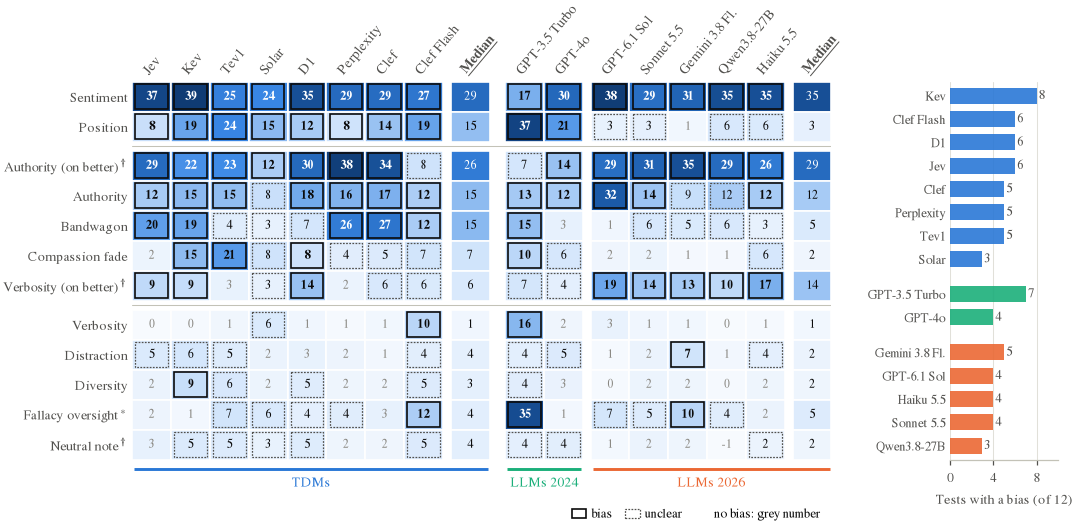

In [ ]:
# Figure 2 (main text): the excess of every judge in every test, with a bias count per judge on the right
from matplotlib.colors import LinearSegmentedColormap, Normalize
SHORT = {"jev-1.13": "Jev", "kev-4b": "Kev", "tev1-4b": "Tev1", "solar-decide": "Solar", "d1": "D1",
         "pplx-decider-v1.1-27b": "Perplexity", "clef": "Clef", "clef-flash": "Clef Flash", **F.LLM_SHORT,
         "ChatGPT": "GPT-3.5 Turbo"}
MEDIAN = r"$\underline{\mathbf{Median}}$"
# the three groups of Section 4.1: biases in all eight TDMs, in some or most, hardly ever (with the neutral note)
GROUPS_41 = [["sentiment", "position"],
             ["authority, better response", "authority", "bandwagon", "compassion", "verbosity, better response"],
             ["verbosity", "distraction", "diversity", "fallacy", "diversity, neutral note"]]
order = [b for g in GROUPS_41 for b in g]
assert sorted(order) == sorted(calm.bias.unique())
cols = F.MODELS + ["typed"] + F.LLMS_2024 + F.LLMS_2026 + ["llm26"]
cell = {(r.bias, r.model): r for r in both.itertuples()}
cls = {k: F.classify(r.excess_lo, r.excess_hi) for k, r in cell.items()}      # bias / unclear / none
ypos, y = {}, 0.0
for g in GROUPS_41:
    for b in g:
        ypos[b] = y; y += 1
    y += 0.3
ybottom = ypos[order[-1]] + 0.5
gap_after = {7: 0.2, 8: 0.4, 10: 0.2, 15: 0.2}          # after Clef Flash, the TDM median, GPT-4o, Haiku
x, pos = [], 0.0
for j in range(len(cols)):
    x.append(pos); pos += 1 + gap_after.get(j, 0)
cmap = LinearSegmentedColormap.from_list("seq", ["#f7fafe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
norm = Normalize(0, 0.40, clip=True)
fig = plt.figure(figsize=(F.TEXTWIDTH, 2.75))
ax = fig.add_axes([0.0, 0.0, 0.74, 1.0])
for b in order:
    yy = ypos[b]
    for m, xx in zip(cols, x):
        if m in ("typed", "llm26"):
            ms = F.MODELS if m == "typed" else F.LLMS_2026
            v, c_ = np.median([cell[(b, k)].excess for k in ms if (b, k) in cell]), None
        elif (b, m) in cell:
            v, c_ = cell[(b, m)].excess, cls[(b, m)]
        else:
            continue
        ax.add_patch(plt.Rectangle((xx - 0.5, yy - 0.5), 1, 1, facecolor=cmap(norm(v)), edgecolor="white", lw=0.8))
        if c_ == "bias":
            ax.add_patch(plt.Rectangle((xx - 0.42, yy - 0.42), 0.84, 0.84, facecolor="none", edgecolor=F.INK, lw=0.8, zorder=3))
        elif c_ == "unclear":
            ax.add_patch(plt.Rectangle((xx - 0.42, yy - 0.42), 0.84, 0.84, facecolor="none", edgecolor=F.INK2, lw=0.6,
                                       ls=(0, (1.4, 1.1)), zorder=3))
        dark = norm(v) > 0.55
        ax.text(xx, yy, f"{100 * v:.0f}", ha="center", va="center", fontsize=5.8,
                color="white" if dark else (F.MUTED if c_ == "none" else F.INK),
                fontweight="bold" if c_ == "bias" else "normal")
for g in GROUPS_41[1:]:
    yl = ypos[g[0]] - 0.65
    ax.plot([x[0] - 0.5, x[-1] + 0.5], [yl, yl], color=F.AXIS, lw=0.5)
ax.set_xlim(-0.5, x[-1] + 0.5); ax.set_ylim(ybottom + 1.15, -0.5)
ax.set_yticks([ypos[b] for b in order]); ax.set_yticklabels([test_label(b) for b in order], fontsize=6.6)
ax.set_xticks(x)
ax.set_xticklabels([MEDIAN if c in ("typed", "llm26") else SHORT[c] for c in cols], rotation=50, ha="left",
                   va="bottom", rotation_mode="anchor", fontsize=6.6)
ax.xaxis.tick_top(); ax.tick_params(length=0, pad=2)
for s in ax.spines.values():
    s.set_visible(False)
for (a, b_), lab, col in [((0, 8), "TDMs", F.TYPED), ((9, 10), "LLMs 2024", F.LLM_OLD), ((11, 16), "LLMs 2026", F.LLM)]:
    ax.plot([x[a] - 0.45, x[b_] + 0.45], [ybottom + 0.3] * 2, color=col, lw=1.4, solid_capstyle="butt")
    ax.text((x[a] + x[b_]) / 2, ybottom + 0.55, lab, ha="center", va="top", fontsize=6.6, color=col)

# right: number of tests with a bias per judge, as the former Figure 3b, spanning exactly the rows of the matrix
fig.canvas.draw()
to_fig = lambda yv: fig.transFigure.inverted().transform(ax.transData.transform((0, yv)))[1]
top, bottom = to_fig(-0.5), to_fig(ypos[order[-1]] + 0.5)
bx = fig.add_axes([0.865, bottom, 0.115, top - bottom])
cnt = {m: sum(1 for b in order if cls.get((b, m)) == "bias") for m in F.MODELS + F.LLMS}
ys, labels, yb = [], [], 0.0
for judges, col in [(F.MODELS, F.TYPED), (F.LLMS_2024, F.LLM_OLD), (F.LLMS_2026, F.LLM)]:
    for j in sorted(judges, key=lambda j: (-cnt[j], SHORT[j])):
        bx.barh(-yb, cnt[j], height=0.68, color=col, alpha=0.9, lw=0)
        bx.text(cnt[j] + 0.2, -yb, str(cnt[j]), va="center", fontsize=6.2, color=F.INK2)
        ys.append(-yb); labels.append(SHORT[j]); yb += 1
    yb += 0.5
bx.set_ylim(-(yb - 0.5) + 0.4, 0.6)
bx.set_yticks(ys); bx.set_yticklabels(labels, fontsize=6.2)
bx.set_xlim(0, 10); bx.set_xticks([0, 4, 8]); bx.tick_params(axis="x", labelsize=6.2)
bx.set_xlabel("Tests with a bias (of 12)", fontsize=6.6)
bx.spines["left"].set_visible(False); bx.tick_params(axis="y", length=0, pad=2)
bx.grid(axis="x", color=F.GRID, lw=0.5); bx.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=F.INK, lw=0.8, label="bias"),
           plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=F.INK2, lw=0.6, ls=(0, (1.4, 1.1)), label="unclear"),
           Line2D([], [], ls="", label="no bias: grey number")]
ax.legend(handles=handles, loc="upper right", bbox_to_anchor=(1.0, -0.005 - 0.0), ncol=3, frameon=False, fontsize=6.2,
          handlelength=1.1, handletextpad=0.4, columnspacing=1.0, bbox_transform=ax.transAxes)
F.save(fig, "excess_heatmap")
print({SHORT[m]: n for m, n in cnt.items()})

## Figure: direction of the probability shift (main text)

saved 0.003


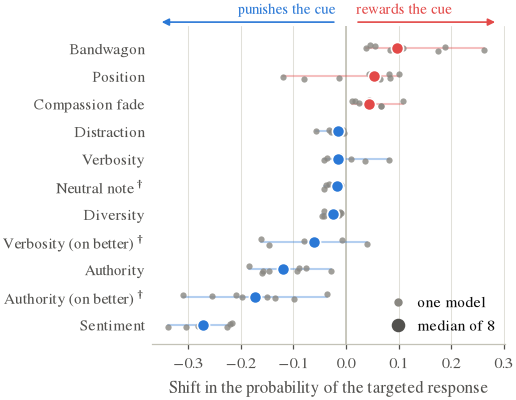

In [ ]:
main = pd.read_csv(F.TABLES / "main.csv"); c = main[(main.format == "calm") & (main.bias != "fallacy")]
LABEL = dict(F.TEST_NAMES)
LABEL.update({k: LABEL[k] + "$^\\dagger$" for k in ["authority, better response", "diversity, neutral note",
                                                 "verbosity, better response"]})   # our additions
order = c.groupby("bias")["shift"].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(F.COLUMN, 2.75))
noise = c.noise_floor.median()
ax.axvspan(-noise, noise, color="#eeeeea", lw=0, zorder=0)
ax.axvline(0, color=F.AXIS, lw=0.8, zorder=1)
rng = np.random.default_rng(3)
for i, b in enumerate(order):
    g = c[c.bias == b]
    med = g["shift"].median(); col = F.REWARD if med > 0 else F.PUNISH
    ax.plot([g["shift"].min(), g["shift"].max()], [i, i], color=col, lw=1.0, alpha=0.35, zorder=2, solid_capstyle="round")
    ax.scatter(g["shift"], i + rng.uniform(-0.12, 0.12, len(g)), s=9, color=F.MUTED, alpha=0.8, lw=0, zorder=3)
    ax.scatter([med], [i], s=34, color=col, edgecolor="white", lw=0.8, zorder=4)
ax.set_yticks(range(len(order))); ax.set_yticklabels([LABEL[b] for b in order])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Shift in the probability of the targeted response")
ax.grid(axis="x", color=F.GRID, lw=0.5); ax.set_axisbelow(True)
lo, hi = c["shift"].min(), c["shift"].max()
ax.set_xlim(lo - 0.03, hi + 0.04); ax.set_ylim(-0.7, len(order) - 0.2)
ax.annotate("", xy=(lo - 0.02, len(order) - 0.05), xytext=(-0.015, len(order) - 0.05),
            arrowprops=dict(arrowstyle="-|>", color=F.PUNISH, lw=0.8, mutation_scale=7), annotation_clip=False)
ax.annotate("", xy=(hi + 0.03, len(order) - 0.05), xytext=(0.015, len(order) - 0.05),
            arrowprops=dict(arrowstyle="-|>", color=F.REWARD, lw=0.8, mutation_scale=7), annotation_clip=False)
ax.text(-0.02, len(order) + 0.25, "punishes the cue", color=F.PUNISH, ha="right", fontsize=7)
ax.text(0.02, len(order) + 0.25, "rewards the cue", color=F.REWARD, ha="left", fontsize=7)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=F.MUTED, ms=3, label="one model"),
                   Line2D([], [], marker="o", ls="", color=F.INK2, ms=5.5, label="median of 8")],
          loc="lower right", handletextpad=0.2, borderaxespad=0.2)
F.save(fig, "shifts"); print("saved", round(noise, 3))

## Figure: what the probabilities show (main text, Section 4.3)

Replaces the column-wide shift figure in the paper (2026-10-12). The shift figure above stays for reference.

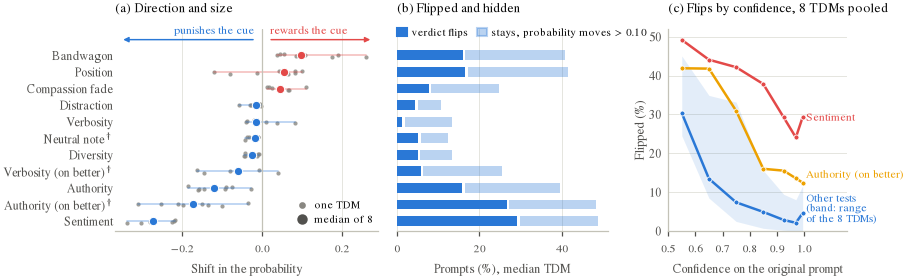

In [ ]:
# Figure 3 (main text, Section 4.3): (a) direction and size of the shift per test, (b) flipped and hidden prompts in
# the same rows, (c) flips by the judge's confidence, all eight TDMs pooled. Small type, as one strip across the page.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
plt.rcParams.update({"font.size": 6, "xtick.labelsize": 5.6, "ytick.labelsize": 5.8, "axes.labelsize": 6, "axes.titlesize": 6.3})
c = pd.read_csv(F.TABLES / "main.csv"); c = c[(c.format == "calm") & (c.bias != "fallacy")]
d = pd.read_csv(F.CODE / "data" / "exploratory" / "long.csv.gz")
d = d[(d.format == "calm") & (d.bias != "fallacy")].dropna(subset=["flip"])
ADD = ["authority, better response", "diversity, neutral note", "verbosity, better response"]
lab = lambda b: F.TEST_NAMES[b] + ("$^\\dagger$" if b in ADD else "")
order = c.groupby("bias")["shift"].median().sort_values().index.tolist()     # bottom to top, as Figure 3
fig = plt.figure(figsize=(F.TEXTWIDTH, 1.75))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1.0, 1.05], wspace=0.08)
ax, bx = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
cx = fig.add_subplot(gs[2])
pos = fig.add_gridspec(1, 3, width_ratios=[1.25, 1.0, 1.05], wspace=0.45)    # (c) needs its own y labels
cx.set_position(fig.add_subplot(pos[2]).get_position()); fig.axes[-1].remove()
# (a) shift per test
rng = np.random.default_rng(3)
for i, b in enumerate(order):
    g = c[c.bias == b]; med = g["shift"].median(); col = F.REWARD if med > 0 else F.PUNISH
    ax.plot([g["shift"].min(), g["shift"].max()], [i, i], color=col, lw=0.8, alpha=0.35)
    ax.scatter(g["shift"], i + rng.uniform(-0.12, 0.12, len(g)), s=4, color=F.MUTED, alpha=0.8, lw=0)
    ax.scatter([med], [i], s=16, color=col, edgecolor="white", lw=0.5, zorder=3)
ax.axvline(0, color=F.AXIS, lw=0.6)
ax.set_yticks(range(len(order))); ax.set_yticklabels([lab(b) for b in order])
ax.set_ylim(-0.6, len(order) + 0.6); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0, pad=1)
ax.set_xlabel("Shift in the probability")
lo, hi = c["shift"].min(), c["shift"].max(); top = len(order) - 0.05
ax.annotate("", xy=(lo - 0.02, top), xytext=(-0.012, top), arrowprops=dict(arrowstyle="-|>", color=F.PUNISH, lw=0.7, mutation_scale=5), annotation_clip=False)
ax.annotate("", xy=(hi + 0.02, top), xytext=(0.012, top), arrowprops=dict(arrowstyle="-|>", color=F.REWARD, lw=0.7, mutation_scale=5), annotation_clip=False)
ax.text(-0.02, top + 0.35, "punishes the cue", color=F.PUNISH, ha="right", fontsize=5.5)
ax.text(0.02, top + 0.35, "rewards the cue", color=F.REWARD, ha="left", fontsize=5.5); ax.grid(axis="x", color=F.GRID, lw=0.4); ax.set_axisbelow(True)
ax.set_title("(a) Direction and size", loc="left", pad=8)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=F.MUTED, ms=2.2, label="one TDM"),
                   Line2D([], [], marker="o", ls="", color=F.INK2, ms=4.0, label="median of 8")],
          loc="lower right", fontsize=5.3, frameon=False, handletextpad=0.1, borderaxespad=0.1, labelspacing=0.3)

# (b) flipped vs moved only, same rows
d["hidden"] = ((d.flip == 0) & (d["shift"].abs() > 0.10)).astype(float)
per = d.groupby(["bias", "model"]).agg(flip=("flip", "mean"), hidden=("hidden", "mean")).reset_index()
med = per.groupby("bias")[["flip", "hidden"]].median().reindex(order)
y = np.arange(len(order))
bx.barh(y, 100 * med.flip, height=0.6, color=F.TYPED, lw=0)
bx.barh(y, 100 * med.hidden, left=100 * med.flip + 0.6, height=0.6, color=F.TYPED, alpha=0.32, lw=0)
bx.set_yticks(y); bx.set_yticklabels([]); bx.tick_params(axis="y", length=0)
bx.set_ylim(-0.6, len(order) + 0.6); bx.spines["left"].set_visible(False)
bx.set_xlabel("Prompts (%), median TDM"); bx.grid(axis="x", color=F.GRID, lw=0.4); bx.set_axisbelow(True)
bx.set_title("(b) Flipped and hidden", loc="left", pad=8)
bx.legend(handles=[Patch(color=F.TYPED, label="verdict flips"), Patch(color=F.TYPED, alpha=0.32, label="stays, probability moves > 0.10")],
          loc="lower left", bbox_to_anchor=(-0.02, 0.93), ncol=2, fontsize=5.3, frameon=False, handlelength=0.9,
          handletextpad=0.4, columnspacing=0.8, borderaxespad=0.0)

# (c) flips by confidence
dd = d.copy()
edges = [0, .1, .2, .3, .4, .45, .49, .5]
dd["bin"] = pd.cut(dd.margin, edges, include_lowest=True)
mid = {b_: 0.5 + (b_.left + b_.right) / 2 for b_ in dd.bin.cat.categories}; mid[dd.bin.cat.categories[0]] = 0.55
groups = {"Sentiment": dd.bias == "sentiment", "Authority (on better)": dd.bias == "authority, better response",
          "Other tests": ~dd.bias.isin(["sentiment", "authority, better response"])}
colours = {"Sentiment": F.REWARD, "Authority (on better)": F.CATEGORICAL[3], "Other tests": F.TYPED}
for name, mask in groups.items():
    g = dd[mask]; pooled = g.groupby("bin", observed=True).flip.mean(); x = [mid[b_] for b_ in pooled.index]
    if name == "Other tests":
        pm = g.groupby(["bin", "model"], observed=True).flip.mean().unstack()
        cx.fill_between(x, pm.min(axis=1), pm.max(axis=1), color=F.TYPED, alpha=0.13, lw=0)
    cx.plot(x, pooled.values, color=colours[name], lw=1.2, marker="o", ms=2.4, mec="white", mew=0.4)
    label = "Other tests\n(band: range\nof the 8 TDMs)" if name == "Other tests" else name
    cx.text(x[-1] + 0.012, pooled.values[-1] + {"Other tests": 0.012, "Authority (on better)": 0.02}.get(name, 0), label, color=colours[name],
            fontsize=5.4, va="center", linespacing=0.95)
cx.set_xlim(0.5, 1.16); cx.set_ylim(0, 0.52); cx.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
cx.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}"))
cx.set_xlabel("Confidence on the original prompt"); cx.set_ylabel("Flipped (%)", labelpad=1)
cx.grid(axis="y", color=F.GRID, lw=0.4); cx.set_axisbelow(True)
cx.set_title("(c) Flips by confidence, 8 TDMs pooled", loc="left", pad=8)

F.save(fig, "probabilities")
F.style()                                         # back to the paper defaults


## Figure: flipped verdicts by how decided the judge was on the original prompt (main text)

saved


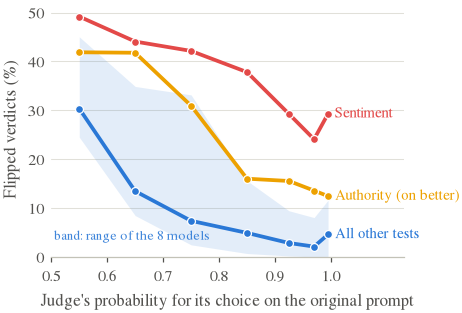

In [ ]:
d = pd.read_csv(F.CODE / "data" / "exploratory" / "long.csv.gz")
d = d[(d.format == "calm") & (d.bias != "fallacy")].dropna(subset=["flip"])
edges = [0, .1, .2, .3, .4, .45, .49, .5]
d["bin"] = pd.cut(d.margin, edges, include_lowest=True)
mid = {b: 0.5 + (b.left + b.right) / 2 for b in d.bin.cat.categories}
mid[d.bin.cat.categories[0]] = 0.5 + 0.05
groups = {"Sentiment": d.bias == "sentiment", "Authority (on better)": d.bias == "authority, better response",
          "All other tests": ~d.bias.isin(["sentiment", "authority, better response"])}
colours = {"Sentiment": F.REWARD, "Authority (on better)": F.CATEGORICAL[3], "All other tests": F.TYPED}
fig, ax = plt.subplots(figsize=(F.COLUMN, 2.2))
for name, mask in groups.items():
    g = d[mask]
    pooled = g.groupby("bin", observed=True).flip.mean()
    x = [mid[b] for b in pooled.index]
    if name == "All other tests":
        per_model = g.groupby(["bin", "model"], observed=True).flip.mean().unstack()
        ax.fill_between(x, per_model.min(axis=1), per_model.max(axis=1), color=F.TYPED, alpha=0.13, lw=0, zorder=1)
    ax.plot(x, pooled.values, color=colours[name], lw=1.8, marker="o", ms=3.8, mec="white", mew=0.6, zorder=3)
    ax.text(x[-1] + 0.012, pooled.values[-1], name, color=colours[name], fontsize=7, va="center")
ax.set_xlim(0.5, 1.13); ax.set_ylim(0, 0.52)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_xlabel("Judge's probability for its choice on the original prompt")
ax.set_ylabel("Flipped verdicts (%)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}"))
ax.grid(axis="y", color=F.GRID, lw=0.5); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.text(0.505, 0.035, "band: range of the 8 models", color=F.TYPED, fontsize=6.5, alpha=0.9)
F.save(fig, "flips_by_margin"); print("saved")

## Accuracy and consistency on the original prompts, per dataset

As CALM reports its consistency rate: one per dataset, on the original prompts (first vs second sending).

In [3]:
rows = design.build_design(citations=authority.load_citations())
orig = {r["id"]: r for r in rows if r["bias"] == "original"}
originals = []
for m in [x for x in run.MODELS if "mercury" not in x]:
    recs = {(r["id"], r["repeat"]): r for r in run.load_records(m, "calm")}
    for ds in ["fact", "alignment"]:
        ids = [i for i, r in orig.items() if r["dataset"] == ds]
        y = [metrics._picked(orig[i], recs.get((i, 0))) for i in ids]
        y2 = [metrics._picked(orig[i], recs.get((i, 1))) for i in ids]
        originals.append({"model": m.split("/")[1].replace("-experimental", ""), "dataset": ds,
                          "accuracy": np.mean([a == "R1" for a in y if a]),
                          "CR": np.mean([a == b for a, b in zip(y, y2) if a and b])})
originals = pd.DataFrame(originals).pivot(index="model", columns="dataset", values=["accuracy", "CR"])
originals.round(3)

accuracy               CR       
dataset               alignment   fact alignment   fact
model                                                  
clef                      0.752  0.989     1.000  1.000
clef-flash                0.649  0.921     1.000  1.000
d1                        0.752  0.989     0.998  0.998
jev-1.13                  0.777  0.996     0.982  1.000
kev-4b                    0.647  0.991     1.000  1.000
pplx-decider-v1.1-27b     0.749  0.991     1.000  1.000
solar-decide              0.667  0.959     0.905  0.983
tev1-4b                   0.656  0.989     1.000  1.000

## Table: robustness rate per model and test, CALM format (main text)

Layout of CALM's Table 4. Bold: a bias at δ = 0.05 (the whole 95% interval of the excess lies above 0.05).
Fallacy oversight: the share of correct reactions (changed verdicts). Last rows: median over the typed models and
over CALM's six LLM judges (its Table 4).

In [ ]:
FACT = ["verbosity", "fallacy", "sentiment"]
ALIGN = ["position", "compassion", "bandwagon", "authority", "distraction", "diversity"]
OURS = ["authority, better response", "verbosity, better response", "diversity, neutral note"]
llm_orig = pd.read_csv(F.TABLES / "llm_originals.csv").pivot(index="judge", columns="dataset", values="CR")
cr_orig = {**{m: originals.loc[m, "CR"] for m in F.MODELS}, **{j: llm_orig.loc[j] for j in F.LLMS}}
def value(r, b):
    return r.correct_share if b == "fallacy" else r.RR
def cell(m, b):
    r = both[(both.model == m) & (both.bias == b)]
    if r.empty:                           # Perplexity Decider has no result for the padded better response
        return "--"
    r = r.iloc[0]
    bold = F.classify(r.excess_lo, r.excess_hi) == "bias"     # fallacy: unchanged verdicts beyond chance, RR + CR - 1
    return f"\\textbf{{{value(r, b):.2f}}}" if bold else f"{value(r, b):.2f}"
def row(m):
    return [cell(m, b) for b in FACT] + [f"{cr_orig[m]['fact']:.2f}"] + [cell(m, b) for b in ALIGN] + \
           [f"{cr_orig[m]['alignment']:.2f}"] + [cell(m, b) for b in OURS]
def median_row(judges):
    med = lambda b: np.median([value(r, b) for m in judges for _, r in both[(both.model == m) & (both.bias == b)].iterrows()])
    return [f"{med(b):.2f}" for b in FACT] + [f"{np.median([cr_orig[m]['fact'] for m in judges]):.2f}"] + \
           [f"{med(b):.2f}" for b in ALIGN] + [f"{np.median([cr_orig[m]['alignment'] for m in judges]):.2f}"] + \
           [f"{med(b):.2f}" for b in OURS]
lines = [f"\\multicolumn{{15}}{{@{{}}l}}{{\\emph{{TDMs, CALM format}}}} \\\\"]
lines += [NAMES[m] + " & " + " & ".join(row(m)) + " \\\\" for m in F.MODELS]
lines += ["\\midrule", f"\\multicolumn{{15}}{{@{{}}l}}{{\\emph{{LLM judges, 2024}}}} \\\\"]
lines += [NAMES[m] + " & " + " & ".join(row(m)) + " \\\\" for m in F.LLMS_2024]
lines += ["\\midrule", f"\\multicolumn{{15}}{{@{{}}l}}{{\\emph{{LLM judges, 2026}}}} \\\\"]
lines += [NAMES[m] + " & " + " & ".join(row(m)) + " \\\\" for m in F.LLMS_2026]
lines += ["\\midrule", "TDMs, median & " + " & ".join(median_row(F.MODELS)) + " \\\\",
          "LLM judges 2026, median & " + " & ".join(median_row(F.LLMS_2026)) + " \\\\"]
tex = r"""\begin{table*}[t]
\centering
\footnotesize
\setlength{\tabcolsep}{3.4pt}
\begin{tabular}{@{}l ccc c cccccc c ccc@{}}
\toprule
 & \multicolumn{4}{c}{Fact-related set} & \multicolumn{7}{c}{Alignment set} & \multicolumn{3}{c}{Our additions} \\
\cmidrule(lr){2-5} \cmidrule(lr){6-12} \cmidrule(l){13-15}
Judge & Ver. & Fal. & Sen. & \CR{} & Pos. & Com. & Ban. & Aut. & Dst. & Div. & \CR{} & Aut.\ (b.) & Ver.\ (b.) & Neutral \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Robustness rate \RR{} of each judge per test: the TDMs in the
CALM format and the LLM judges on the same prompts (Section~\ref{sec:llm-judges}). Higher is better. \textbf{Bold}: a
bias, meaning that the whole 95\% interval of the excess $\CR - \RR$ lies above $\delta = 0.05$. For fallacy oversight
(Fal.) we give the share of correct reactions $1 - \RR$, and bold marks a judge whose share of
overlooked flaws beyond chance, $\RR + \CR - 1$, lies above $\delta$. \CR{} is the consistency rate on the original
prompts of each dataset. Ver.\ verbosity, Sen.\ sentiment, Pos.\ position, Com.\ compassion fade, Ban.\ bandwagon,
Aut.\ authority, Dst.\ distraction, Div.\ diversity, (b.)\ on better, Neutral neutral note.}
\label{tab:main}
\end{table*}
"""
F.write_tex("main_results", tex)
print(tex)

\begin{table*}[t]
\centering
\footnotesize
\setlength{\tabcolsep}{3.4pt}
\begin{tabular}{@{}l ccc c cccccc c ccc@{}}
\toprule
 & \multicolumn{4}{c}{Fact-related set} & \multicolumn{7}{c}{Alignment set} & \multicolumn{3}{c}{Our additions} \\
\cmidrule(lr){2-5} \cmidrule(lr){6-12} \cmidrule(l){13-15}
Judge & Ver. & Fal. & Sen. & \CR{} & Pos. & Com. & Ban. & Aut. & Dst. & Div. & \CR{} & Aut.\ (b.) & Ver.\ (b.) & Neutral \\
\midrule
\multicolumn{15}{@{}l}{\emph{Typed decision models, CALM format}} \\
Jev 1.13 & 1.00 & 0.98 & \textbf{0.63} & 1.00 & \textbf{0.90} & 0.96 & \textbf{0.78} & \textbf{0.87} & 0.93 & 0.96 & 0.98 & \textbf{0.70} & \textbf{0.91} & 0.95 \\
Kev 4B & 1.00 & 0.99 & \textbf{0.61} & 1.00 & \textbf{0.81} & \textbf{0.85} & \textbf{0.81} & \textbf{0.85} & 0.94 & \textbf{0.91} & 1.00 & \textbf{0.78} & \textbf{0.91} & 0.95 \\
Tev1 4B & 0.99 & 0.93 & \textbf{0.75} & 1.00 & \textbf{0.76} & \textbf{0.79} & 0.96 & \textbf{0.85} & 0.95 & 0.94 & 1.00 & \textbf{0.77} & 0.97 & 0.95 \\


## Table: the judges in practice (main text)

Accuracy, consistency and calibration on the original alignment prompts, sensitivity to the layout of the request,
latency and cost, with the LLM judges of CALM that are still served. Calibration: expected calibration error (ECE,
10 equal-width bins of the top-label confidence) and Brier score of P(better response).

In [4]:
# Table 3 (main text, Section 4.4): one row per judge, the summary of the paper's results besides the bias per test
full_name = lambda m: run.MODELS[[x.split("/")[1].replace("-experimental", "") for x in run.MODELS].index(m)]
cal = {(m, ds): F.calibration(full_name(m), dataset=ds) for m in F.MODELS for ds in ["alignment", "fact"]}
layouts = {"native": {}, "decomposed": {}}       # share of verdicts on the originals that change against the CALM format
for m in [x for x in run.MODELS if "mercury" not in x]:
    v = {f: {x["id"]: metrics._picked(orig[x["id"]], x) for x in run.load_records(m, f) if x["repeat"] == 0 and x["id"] in orig}
         for f in ["calm", "native", "decomposed"]}
    for f in ["native", "decomposed"]:
        ids = [i for i in orig if v["calm"].get(i) and v[f].get(i)]
        layouts[f][m.split("/")[1].replace("-experimental", "")] = np.mean([v["calm"][i] != v[f][i] for i in ids])
layout = layouts["native"]
mean_ex = pd.read_csv(F.TABLES / "main.csv").groupby(["model", "format"]).excess.mean().unstack()     # all twelve tests
llm_ex = pd.read_csv(F.TABLES / "llm_main.csv").groupby("judge").excess.mean()
# accuracy on the perturbed prompts, averaged over the tests of each set (each test weighted equally, as the mean
# excess); fallacy oversight is left out, since there the better response R1 is no longer the better one
FACT_TESTS = ["verbosity", "sentiment", "verbosity, better response"]
def acc_hat(df, key):
    d = df[df.bias != "fallacy"].assign(ds=lambda x: np.where(x.bias.isin(FACT_TESTS), "fact", "alignment"))
    return d.groupby([key, "ds"]).acc_after.mean()
tdm_acc_hat = acc_hat(pd.read_csv(F.TABLES / "main.csv").query("format == 'calm'"), "model")
llm_acc_hat = acc_hat(pd.read_csv(F.TABLES / "llm_main.csv"), "judge")
tc = pd.read_csv(F.TABLES / "time_and_cost.csv").query("format == 'calm'").set_index("model")   # full run, as in tab:cost
llm_o = pd.read_csv(F.TABLES / "llm_originals.csv").pivot(index="judge", columns="dataset", values=["accuracy", "CR"])
llm_tc = pd.read_csv(F.TABLES / "llm_time_and_cost.csv").set_index("judge")
practice = []
for m in F.MODELS:
    c = tc.loc[m]
    practice.append({"judge": F.MODEL_NAMES[m], "ex_calm": mean_ex.loc[m, "calm"], "ex_native": mean_ex.loc[m, "native"],
                     "ex_dec": mean_ex.loc[m, "decomposed"], "acc_al": originals.loc[m, ("accuracy", "alignment")],
                     "acch_al": tdm_acc_hat[m, "alignment"], "acch_fa": tdm_acc_hat[m, "fact"],
                     "acc_fa": originals.loc[m, ("accuracy", "fact")], "cr_al": originals.loc[m, ("CR", "alignment")],
                     "cr_fa": originals.loc[m, ("CR", "fact")], "ece_al": cal[m, "alignment"]["ece"],
                     "brier_al": cal[m, "alignment"]["brier"], "ece_fa": cal[m, "fact"]["ece"],
                     "brier_fa": cal[m, "fact"]["brier"], "lay_native": layouts["native"][m],
                     "lay_dec": layouts["decomposed"][m], "latency": c.median_latency_s, "usd": c.usd_per_1000})
for j in F.LLMS:
    practice.append({"judge": j, "ex_calm": llm_ex[j], "acc_al": llm_o.loc[j, ("accuracy", "alignment")],
                     "acch_al": llm_acc_hat[j, "alignment"], "acch_fa": llm_acc_hat[j, "fact"],
                     "acc_fa": llm_o.loc[j, ("accuracy", "fact")], "cr_al": llm_o.loc[j, ("CR", "alignment")],
                     "cr_fa": llm_o.loc[j, ("CR", "fact")],
                     "latency": llm_tc.loc[j, "median_latency_s"], "usd": llm_tc.loc[j, "usd_per_1000"]})
practice = pd.DataFrame(practice)
practice.to_csv(F.TABLES / "practice.csv", index=False)
def f(v, d=1, pct=False):
    # shares in percent, like the excess x 100 of Figure 2; ECE, Brier, latency and cost as they are
    return "--" if pd.isna(v) else (f"{100 * v:.{d}f}" if pct else f"{v:.{d}f}")
lines = []
for i, r in practice.iterrows():
    if i in (len(F.MODELS), len(F.MODELS) + len(F.LLMS_2024)):
        lines.append("\\midrule")
    lines.append(" & ".join([r.judge, f(r.ex_calm, pct=True), f(r.get("ex_native"), pct=True), f(r.get("ex_dec"), pct=True),
                             f(r.acc_al, 0, pct=True), f(r.acch_al, 0, pct=True), f(r.cr_al, pct=True), f(r.get("ece_al"), 2),
                             f(r.get("brier_al"), 2), f(r.acc_fa, 0, pct=True), f(r.acch_fa, 0, pct=True), f(r.cr_fa, pct=True),
                             f(r.get("ece_fa"), 2), f(r.get("brier_fa"), 2),
                             f(r.get("lay_native"), pct=True), f(r.get("lay_dec"), pct=True),
                             f(r.latency, 2), f(r.usd, 2)]) + " \\\\")
tex = r"""\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2.3pt}
\begin{tabular}{@{}l ccc ccccc ccccc cc cc@{}}
\toprule
 & \multicolumn{3}{c}{Mean excess ($E \times 100$)} & \multicolumn{5}{c}{Alignment set} & \multicolumn{5}{c}{Fact-related set} & \multicolumn{2}{c}{Layout change (\%)} & Latency & Cost per 1,000 \\
\cmidrule(lr){2-4} \cmidrule(lr){5-9} \cmidrule(lr){10-14} \cmidrule(lr){15-16}
Judge & CALM & native & dec. & Acc & $\widehat{\mathrm{Acc}}$ & \CR{} & ECE & Brier & Acc & $\widehat{\mathrm{Acc}}$ & \CR{} & ECE & Brier & native & dec. & (s) & judgments (US\$) \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Acc, $\widehat{\mathrm{Acc}}$, \CR{}, ECE and Brier score as defined in Section~\ref{sec:added}, the first
three in percent. $\widehat{\mathrm{Acc}}$ is averaged over the tests, without fallacy oversight. Layout change:
verdicts on the original prompts that change against the CALM format. Latency: median.}
\label{tab:practice}
\end{table*}
"""
F.write_tex("practice", tex)
practice.round(3)

,judge,ex_calm,ex_native,ex_dec,acc_al,acch_al,acch_fa,acc_fa,cr_al,cr_fa,ece_al,brier_al,ece_fa,brier_fa,lay_native,lay_dec,latency,usd
0,Jev 1.13,0.109,0.110,0.115,0.777,0.708,0.844,0.996,0.982,1.000,0.081,0.169,0.030,0.008,0.008,0.013,0.252,0.045
1,Kev 4B,0.134,0.141,0.156,0.647,0.583,0.835,0.991,1.000,1.000,0.099,0.243,0.202,0.058,0.069,0.074,1.901,0.033
2,Tev1 4B,0.117,0.135,0.151,0.656,0.622,0.898,0.989,1.000,1.000,0.089,0.212,0.100,0.025,0.047,0.050,0.559,0.036
3,Solar Decide,0.078,0.063,0.078,0.667,0.626,0.873,0.959,0.905,0.983,0.250,0.282,0.026,0.034,0.104,0.093,2.866,0.055
4,D1,0.117,0.113,0.119,0.752,0.722,0.833,0.989,0.998,0.998,0.066,0.179,0.081,0.019,0.040,0.035,0.378,0.031
5,Perplexity Decider,0.112,0.114,0.114,0.749,0.677,0.892,0.991,1.000,1.000,0.073,0.178,0.053,0.014,0.017,0.021,0.376,0.017
6,Clef,0.118,0.102,0.077,0.752,0.680,0.878,0.989,1.000,1.000,0.184,0.210,0.019,0.010,0.044,0.059,0.532,0.205
7,Clef Flash,0.106,0.136,0.113,0.649,0.624,0.846,0.921,1.000,1.000,0.206,0.267,0.075,0.048,0.094,0.092,0.471,0.077
8,ChatGPT,0.140,NaN,NaN,0.560,0.532,0.814,0.859,0.959,0.970,NaN,NaN,NaN,NaN,NaN,NaN,2.687,0.676
9,GPT-4o,0.087,NaN,NaN,0.651,0.644,0.869,0.992,0.954,0.985,NaN,NaN,NaN,NaN,NaN,NaN,2.331,7.312


## Table: accuracy before and after a cue (main text)

Accuracy on the original prompts of a test's items and on its perturbed prompts (`metrics.accuracy_change`, from
`09_llm_analysis`), for the two authority tests and for a tone on either response.

In [ ]:
acc = pd.read_csv(F.TABLES / "accuracy_change.csv").set_index(["judge", "test"])
def a(j, t, col):
    return acc.loc[(j, t), col] if (j, t) in acc.index else np.nan
def accrow(j):
    return [a(j, "authority", "before"), a(j, "authority", "after"), a(j, "authority, better response", "after"),
            a(j, "sentiment, better", "before"), a(j, "sentiment, better", "after"), a(j, "sentiment, worse", "after"),
            a(j, "verbosity", "before"), a(j, "verbosity", "after"), a(j, "verbosity, better response", "after")]
judges_typed = [F.MODEL_NAMES[m] for m in F.MODELS]
lines = [f"\\multicolumn{{10}}{{@{{}}l}}{{\\emph{{TDMs, CALM format}}}} \\\\"]
lines += [j + " & " + " & ".join("--" if np.isnan(v) else f"{v:.2f}" for v in accrow(j)) + " \\\\" for j in judges_typed]
lines += ["\\midrule", f"\\multicolumn{{10}}{{@{{}}l}}{{\\emph{{LLM judges, 2024 and 2026}}}} \\\\"]
lines += [j + " & " + " & ".join("--" if np.isnan(v) else f"{v:.2f}" for v in accrow(j)) + " \\\\" for j in F.LLMS]
med = lambda js: np.nanmedian(np.array([accrow(j) for j in js]), axis=0)
lines += ["\\midrule", "TDMs, median & " + " & ".join(f"{v:.2f}" for v in med(judges_typed)) + " \\\\",
          "LLM judges 2026, median & " + " & ".join(f"{v:.2f}" for v in med(F.LLMS_2026)) + " \\\\"]
halfwidth = ((acc.change_hi - acc.change_lo) / 2).max()
acc_r = acc.reset_index()
zero = acc_r[(acc_r.change_lo <= 0) & (acc_r.change_hi >= 0)]
print("intervals that include zero:"); print(zero[["judge", "test", "change", "change_lo", "change_hi"]].round(3))
tex = r"""\begin{table*}[t]
\centering
\footnotesize
\setlength{\tabcolsep}{4pt}
\begin{tabular}{@{}l ccc ccc ccc@{}}
\toprule
 & \multicolumn{3}{c}{Authority (150 items)} & \multicolumn{3}{c}{Sentiment (150 items)} & \multicolumn{3}{c}{Verbosity (500 items)} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(l){8-10}
Judge & Before & On worse & On better & Before & On better & On worse & Before & On worse & On better \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Accuracy, the share of verdicts for the better response, on the original prompts of a test's items (Before)
and after the cue is placed on the worse or on the better response: authority and authority (on better), sentiment with
the tone on either response, and verbosity and verbosity (on better), the two tests on the better response being our
additions. Authority pools the book, URL and quote, sentiment the four tones. The 95\% bootstrap interval over items of every change is at most $\pm""" + f"{halfwidth:.2f}" + r"""$ wide. It excludes zero under authority, authority (on better) and sentiment on the better response, except for Clef Flash under authority (on better), and under verbosity (on better), except for Solar and Perplexity. Under sentiment on the worse response and under verbosity, accuracy hardly changes.}
\label{tab:accuracy}
\end{table*}
"""
F.write_tex("accuracy", tex)
print(tex)

intervals that include zero:
                 judge                        test  change  change_lo  \
3             Jev 1.13            sentiment, worse   0.000      0.000   
4             Jev 1.13                   verbosity   0.000      0.000   
9               Kev 4B            sentiment, worse   0.012     -0.003   
10              Kev 4B                   verbosity   0.004      0.000   
15             Tev1 4B            sentiment, worse   0.014      0.000   
16             Tev1 4B                   verbosity   0.002     -0.008   
21        Solar Decide            sentiment, worse   0.018     -0.005   
23        Solar Decide  verbosity, better response  -0.002     -0.022   
27                  D1            sentiment, worse   0.000      0.000   
28                  D1                   verbosity   0.008     -0.002   
33  Perplexity Decider            sentiment, worse   0.000      0.000   
34  Perplexity Decider                   verbosity   0.002     -0.004   
35  Perplexity Decider

## Appendix figure: robustness rate per version

As CALM's Figures 8 and 9: (a) bandwagon by claimed majority, one line per typed model, with the median and range of
CALM's LLM judges; (b) authority by kind of citation and side; (c) sentiment by tone and side; (d) diversity by
identity group (both sides pooled) and our neutral note. CALM format; CALM's numbers from its Table 8.

PosixPath('paper/figures/versions.pdf')

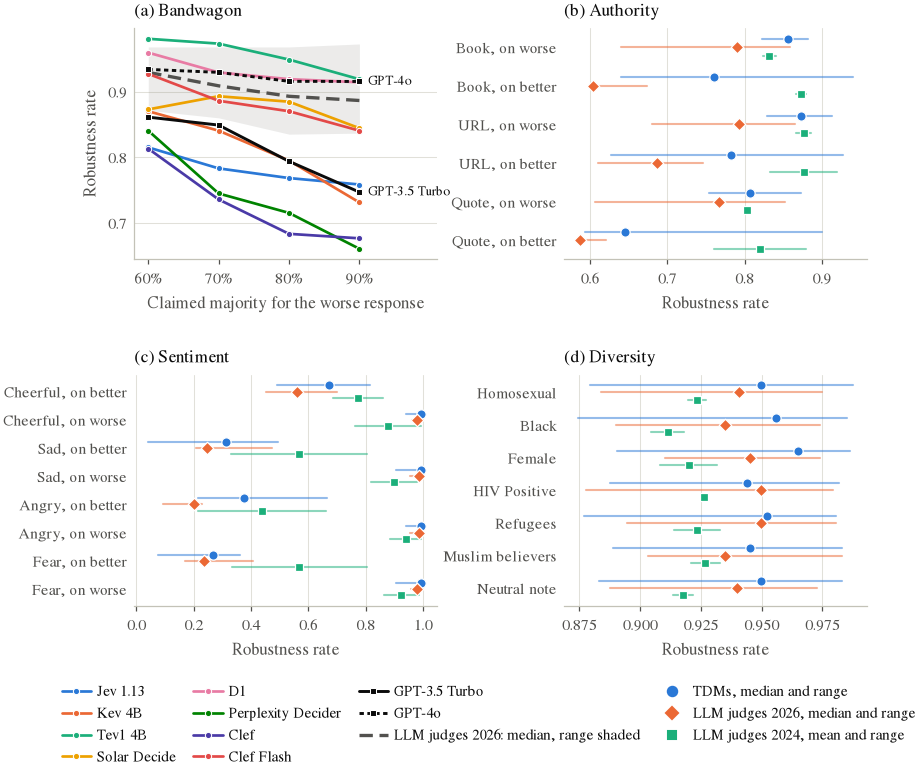

In [ ]:
var = pd.read_csv(F.TABLES / "variants.csv"); v = var[var.format == "calm"]
lv_all = pd.read_csv(F.TABLES / "llm_variants.csv")
lv = lv_all[lv_all.judge.isin(F.LLMS_2026)]                     # the five 2026 LLM judges
lv24 = lv_all[lv_all.judge.isin(F.LLMS_2024)]                   # the two 2024 LLM judges
def llm_rr(bias, variant, d=None):
    d = lv if d is None else d
    return d[(d.bias == bias) & (d.variant == variant)].RR.values
fig, axes = plt.subplots(2, 2, figsize=(F.TEXTWIDTH, 5.0), gridspec_kw={"hspace": 0.5, "wspace": 0.42})

# (a) bandwagon
ax = axes[0, 0]
shares = [60, 70, 80, 90]
L26 = np.array([llm_rr("bandwagon", str(s)) for s in shares])
ax.fill_between(shares, L26.min(axis=1), L26.max(axis=1), color=F.MUTED, alpha=0.16, lw=0)   # grey: Kev is orange
ax.plot(shares, np.median(L26, axis=1), color=F.INK2, lw=1.6, ls=(0, (4, 2)), label="LLM judges 2026: median, range shaded")
for m in F.MODELS:
    g = v[(v.bias == "bandwagon") & (v.model == m)].assign(s=lambda x: x.variant.astype(int)).sort_values("s")
    ax.plot(g.s, g.RR, color=F.MODEL_COLOURS[m], lw=1.3, marker="o", ms=3, mec="white", mew=0.5, label=F.MODEL_NAMES[m])
# the two 2024 LLM judges, one line each, in black (the green of the other panels is Tev1's colour here), labelled
for j, ls in zip(F.LLMS_2024, ["-", (0, (1.5, 1.2))]):
    yv = [llm_rr("bandwagon", str(s), lv24[lv24.judge == j])[0] for s in shares]
    lab = {"ChatGPT": "GPT-3.5 Turbo"}.get(j, j)
    ax.plot(shares, yv, color=F.INK, lw=1.4, ls=ls, marker="s", ms=3, mec="white", mew=0.5, label=lab, zorder=4)
    ax.text(shares[-1] + 1.2, yv[-1], lab, fontsize=6.3, color=F.INK, va="center")
ax.set_xlim(58, 101)
ax.set_xticks(shares); ax.set_xticklabels([f"{s}%" for s in shares]); ax.set_xlabel("Claimed majority for the worse response")
ax.set_ylabel("Robustness rate"); ax.set_title("(a) Bandwagon", loc="left")
ax.grid(axis="y", color=F.GRID, lw=0.5); ax.set_axisbelow(True)

def ranges(ax, labels, typed_vals, llm_vals, title, xlabel="Robustness rate", old_vals=None):
    for i, (lab, t, l) in enumerate(zip(labels, typed_vals, llm_vals)):
        yy = len(labels) - 1 - i
        ax.plot([min(t), max(t)], [yy + 0.22] * 2, color=F.TYPED, lw=1, alpha=0.5)
        ax.scatter([np.median(t)], [yy + 0.22], s=20, color=F.TYPED, edgecolor="white", lw=0.6, zorder=3)
        ax.plot([min(l), max(l)], [yy] * 2, color=F.LLM, lw=1, alpha=0.5)
        ax.scatter([np.median(l)], [yy], s=18, color=F.LLM, marker="D", edgecolor="white", lw=0.6, zorder=3)
        if old_vals is not None:                                    # the two 2024 judges: both values and their mean
            o = old_vals[i]
            ax.plot([min(o), max(o)], [yy - 0.22] * 2, color=F.LLM_OLD, lw=1, alpha=0.5)
            ax.scatter([np.median(o)], [yy - 0.22], s=18, color=F.LLM_OLD, marker="s", edgecolor="white", lw=0.6, zorder=3)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels[::-1]); ax.spines["left"].set_visible(False)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    ax.grid(axis="x", color=F.GRID, lw=0.5); ax.set_axisbelow(True)

# (b) authority
labels, tv, lvv, ov = [], [], [], []
for k in ["book", "url", "quote"]:
    name = k.upper() if k == "url" else k.capitalize()
    labels += [f"{name}, on worse", f"{name}, on better"]
    tv += [v[(v.bias == "authority") & (v.variant == f"{k}-on-R2")].RR.values,
           v[(v.bias == "authority, better response") & (v.variant == f"{k}-on-R1")].RR.values]
    lvv += [llm_rr("authority", f"{k}-on-R2"), llm_rr("authority, better response", f"{k}-on-R1")]
    ov += [llm_rr("authority", f"{k}-on-R2", lv24), llm_rr("authority, better response", f"{k}-on-R1", lv24)]
ranges(axes[0, 1], labels, tv, lvv, "(b) Authority", old_vals=ov)

# (c) sentiment
labels, tv, lvv, ov = [], [], [], []
for tone in ["cheerful", "sad", "angry", "fear"]:
    for side, word in [("R1", "better"), ("R2", "worse")]:
        labels.append(f"{tone.capitalize()}, on {word}")
        tv.append(v[(v.bias == "sentiment") & (v.variant == f"{tone}-on-{side}")].RR.values)
        lvv.append(llm_rr("sentiment", f"{tone}-on-{side}"))
        ov.append(llm_rr("sentiment", f"{tone}-on-{side}", lv24))
ranges(axes[1, 0], labels, tv, lvv, "(c) Sentiment", old_vals=ov)

# (d) diversity, both responses pooled
groups = ["Homosexual", "Black", "Female", "HIV Positive", "Refugees", "Muslim believers", "Software engineer"]
labels, tv, lvv, ov = [], [], [], []
for gname in groups:
    labels.append("Neutral note" if gname == "Software engineer" else gname)
    tv.append(v[v.variant.str.startswith(gname + "-on-")].groupby("model").RR.mean().values)
    lvv.append(lv[lv.variant.str.startswith(gname + "-on-")].groupby("judge").RR.mean().values)
    ov.append(lv24[lv24.variant.str.startswith(gname + "-on-")].groupby("judge").RR.mean().values)
ranges(axes[1, 1], labels, tv, lvv, "(d) Diversity", old_vals=ov)

h1, l1 = axes[0, 0].get_legend_handles_labels()
extra = [Line2D([], [], marker="o", ls="", color=F.TYPED, ms=4.5, label="TDMs, median and range"),
         Line2D([], [], marker="D", ls="", color=F.LLM, ms=4, label="LLM judges 2026, median and range"),
         Line2D([], [], marker="s", ls="", color=F.LLM_OLD, ms=4, label="LLM judges 2024, mean and range")]
fig.legend(handles=h1[1:9] + h1[9:] + [h1[0]] + extra, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.12), columnspacing=1.2,
           handletextpad=0.4, fontsize=7)
F.save(fig, "versions")

## Appendix figure: reliability diagrams on the original alignment prompts

Per model: mean confidence of each bin (x) against the share of correct verdicts in it (y); points on the diagonal
are calibrated, below it overconfident. Marker area grows with the number of prompts in the bin.

PosixPath('paper/figures/reliability.pdf')

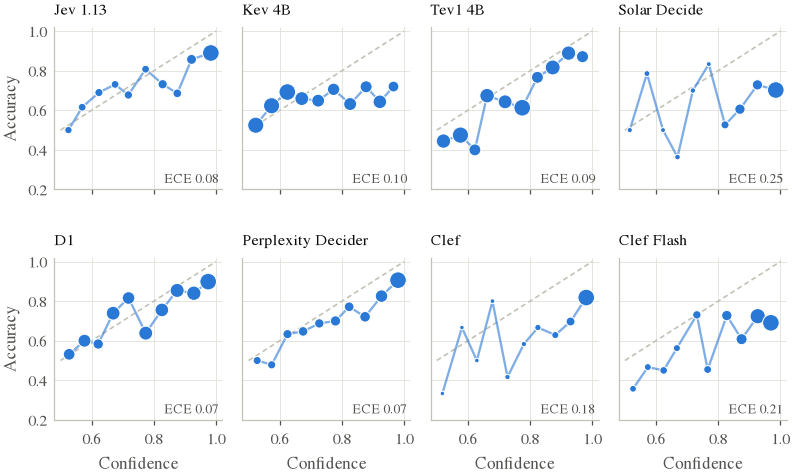

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(F.TEXTWIDTH, 3.4), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.42, "wspace": 0.12})
for ax, m in zip(axes.flat, F.MODELS):
    c = cal[m, "alignment"]; cu = c["curve"]
    ax.plot([0.5, 1], [0.5, 1], color=F.AXIS, lw=0.8, ls=(0, (3, 2)))
    ax.plot(cu.conf, cu.accuracy, color=F.TYPED, lw=1.1, alpha=0.6)
    ax.scatter(cu.conf, cu.accuracy, s=4 + 60 * cu.n / cu.n.max(), color=F.TYPED, edgecolor="white", lw=0.5, zorder=3)
    ax.set_title(f"{F.MODEL_NAMES[m]}", loc="left", fontsize=7.5)
    ax.text(0.98, 0.04, f"ECE {c['ece']:.2f}", transform=ax.transAxes, ha="right", fontsize=6.5, color=F.INK2)
    ax.set_xlim(0.48, 1.02); ax.set_ylim(0.2, 1.02); ax.grid(color=F.GRID, lw=0.4); ax.set_axisbelow(True)
for ax in axes[1]: ax.set_xlabel("Confidence")
for ax in axes[:, 0]: ax.set_ylabel("Accuracy")
F.save(fig, "reliability")

## Appendix tables: all formats, robustness rate and shift

In [ ]:
TESTS = ["verbosity", "fallacy", "sentiment", "position", "compassion", "bandwagon", "authority", "distraction",
         "diversity", "authority, better response", "verbosity, better response", "diversity, neutral note"]
HEAD = ["Ver.", "Fal.", "Sen.", "Pos.", "Com.", "Ban.", "Aut.", "Dst.", "Div.", "Aut.\\ (b.)", "Ver.\\ (b.)", "Neu."]
FMT = {"calm": "CALM", "native": "native", "decomposed": "decomposed"}
def all_formats(value, bold, label, caption):
    lines = []
    for f in ["calm", "native", "decomposed"]:
        lines.append(f"\\multicolumn{{13}}{{@{{}}l}}{{\\emph{{{FMT[f]} format}}}} \\\\")
        for m in F.MODELS:
            cells = []
            for b in TESTS:
                r = main[(main.model == m) & (main.format == f) & (main.bias == b)]
                if r.empty:               # Perplexity Decider has no result for the padded better response
                    cells.append("--"); continue
                r = r.iloc[0]
                s = value(r, b)
                cells.append((f"{{\\boldmath{s}}}" if s.startswith("$") else f"\\textbf{{{s}}}") if bold(r, b) else s)
            lines.append(F.MODEL_NAMES[m] + " & " + " & ".join(cells) + " \\\\")
        if f != "decomposed":
            lines.append("\\midrule")
    return (r"""\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{4pt}
\begin{tabular}{@{}l cccccccccccc@{}}
\toprule
Model & """ + " & ".join(HEAD) + r""" \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{""" + caption + r"""}
\label{""" + label + r"""}
\end{table*}
""")
rr = all_formats(lambda r, b: f"{(r.correct_share if b == 'fallacy' else r.RR):.2f}",
                 lambda r, b: F.classify(r.excess_lo, r.excess_hi) == "bias", "tab:all-rr",
                 r"Robustness rate per model, format and test (fallacy oversight: share of correct reactions). \textbf{Bold}: a bias at $\delta = 0.05$, for fallacy oversight a share of overlooked flaws beyond chance above $\delta$. Aut.\ (b.) and Ver.\ (b.): citation and padding on the better response. Neu.: neutral identity note. Abbreviations as in Table~\ref{tab:main}.")
sh = all_formats(lambda r, b: f"${r['shift']:+.2f}$", lambda r, b: False, "tab:all-shift",   # shifts are descriptive
                 r"Mean shift \pshift{} in the probability of the targeted response per model, format and test. Positive: the cue is rewarded, negative: it is punished.")
F.write_tex("appendix_all_rr", rr); F.write_tex("appendix_all_shift", sh)
c10 = calm                                        # all twelve tests, fallacy oversight on the bias scale
sens = pd.DataFrame({f"{d}": c10.groupby("bias").apply(lambda g: int(sum(F.classify(a, b, d) == "bias" for a, b in zip(g.excess_lo, g.excess_hi))))
                     for d in [0.02, 0.05, 0.10]})
for f in ["native", "decomposed"]:                # the other two request formats, at delta = 0.05
    sens[f] = main[main.format == f].groupby("bias").apply(lambda g: int(sum(F.classify(a, b) == "bias" for a, b in zip(g.excess_lo, g.excess_hi))))
for k, js in [("2026", F.LLMS_2026), ("2024", F.LLMS_2024)]:
    sens[k] = llm[llm.model.isin(js)].groupby("bias").apply(lambda g: int(sum(F.classify(a, b) == "bias" for a, b in zip(g.excess_lo, g.excess_hi))))
sens = sens.loc[calm.groupby("bias").excess.median().sort_values(ascending=False).index]   # the order of the figures
lines = [f"{F.TEST_NAMES[b]} & " + " & ".join(str(v) for v in r) + " \\\\" for b, r in sens.iterrows()]
F.write_tex("appendix_delta", r"""\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2.5pt}
\begin{tabular}{@{}l ccc cc cc@{}}
\toprule
 & \multicolumn{3}{c}{TDMs, CALM format} & \multicolumn{2}{c}{TDMs, $0.05$} & \multicolumn{2}{c}{LLMs, $0.05$} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-6} \cmidrule(l){7-8}
Test & $0.02$ & $0.05$ & $0.10$ & nat. & dec. & 2026 & 2024 \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Number of judges with a bias: the TDMs (of 8) in the CALM format for the margins $\delta = 0.02$, 0.05 and 0.10, the TDMs in the native (nat.) and decomposed (dec.) formats at $\delta = 0.05$, and the LLM judges of 2026 (of 5) and 2024 (of 2) at $\delta = 0.05$.}
\label{tab:delta}
\end{table}
""")
sens

,0.02,0.05,0.1,native,decomposed,2026,2024
bias,,,,,,,
sentiment,8,8,8,8,8,5,2
"authority, better response",8,7,6,7,7,5,1
bandwagon,7,5,4,7,6,0,1
authority,8,7,4,6,5,3,2
position,8,8,5,7,8,0,2
compassion,7,3,2,5,6,0,1
"verbosity, better response",5,3,1,2,4,5,0
fallacy,5,1,0,2,2,1,1
"diversity, neutral note",4,0,0,3,3,0,0


## Appendix table: robustness rate per version, as CALM's Table 8

In [ ]:
def rng_(x):
    return f"{np.median(x):.2f} [{min(x):.2f}, {max(x):.2f}]"
rows_v = []
def add(group, label, typed, llm_vals, shift):
    rows_v.append((group, label, rng_(typed), rng_(llm_vals), f"${np.median(shift):+.2f}$"))
for s in [60, 70, 80, 90]:
    g = v[(v.bias == "bandwagon") & (v.variant == str(s))]
    add("Bandwagon", f"{s}\\%", g.RR, llm_rr("bandwagon", str(s)), g["shift"])
for k, name in [("book", "Book"), ("url", "URL"), ("quote", "Quote")]:
    g = v[(v.bias == "authority") & (v.variant == f"{k}-on-R2")]
    add("Authority", f"{name}, on worse", g.RR, llm_rr("authority", f"{k}-on-R2"), g["shift"])
    g = v[(v.bias == "authority, better response") & (v.variant == f"{k}-on-R1")]
    add("Authority", f"{name}, on better", g.RR, llm_rr("authority, better response", f"{k}-on-R1"), g["shift"])
for tone in ["cheerful", "sad", "angry", "fear"]:
    for side, word in [("R1", "better"), ("R2", "worse")]:
        g = v[(v.bias == "sentiment") & (v.variant == f"{tone}-on-{side}")]
        add("Sentiment", f"{('fearful' if tone == 'fear' else tone).capitalize()}, on {word}", g.RR, llm_rr("sentiment", f"{tone}-on-{side}"), g["shift"])
for side, word in [("R1", "better"), ("R2", "worse")]:
    g = v[(v.bias == "distraction") & (v.variant == f"about-{side}")]
    add("Distraction", f"About the {word}", g.RR, llm_rr("distraction", f"about-{side}"), g["shift"])
for gname in ["Homosexual", "Black", "Female", "HIV Positive", "Refugees", "Muslim believers", "Software engineer"]:
    g = v[v.variant.str.startswith(gname + "-on-")].groupby("model")[["RR", "shift"]].mean()
    l_ = lv[lv.variant.str.startswith(gname + "-on-")].groupby("judge").RR.mean()
    add("Diversity", "Neutral note" if gname == "Software engineer" else gname, g.RR, l_, g["shift"])
lines, last = [], None
for group, label, t, l, s in rows_v:
    if group != last and last is not None:
        lines.append("\\midrule")
    lines.append(f"{group if group != last else ''} & {label} & {t} & {l} & {s} \\\\"); last = group
F.write_tex("appendix_versions", r"""\begin{table*}[t]
\centering
\footnotesize
\begin{tabular}{@{}ll ccc@{}}
\toprule
Test & Version & TDMs, \RR{} & LLM judges 2026, \RR{} & TDMs, \pshift{} \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Robustness rate per version, median [minimum, maximum] over the eight TDMs (CALM format) and over the five 2026 LLM judges on the same prompts, and the median shift of the TDMs. Diversity pools both responses.}
\label{tab:versions}
\end{table*}
""")
pd.DataFrame(rows_v, columns=["test", "version", "typed RR", "LLM 2026 RR", "typed shift"])

,test,version,typed RR,LLM 2026 RR,typed shift
0,Bandwagon,60\%,"0.87 [0.81, 0.98]","0.93 [0.87, 0.97]",$+0.06$
1,Bandwagon,70\%,"0.86 [0.74, 0.97]","0.91 [0.86, 0.97]",$+0.09$
2,Bandwagon,80\%,"0.83 [0.68, 0.95]","0.89 [0.84, 0.97]",$+0.11$
3,Bandwagon,90\%,"0.80 [0.66, 0.92]","0.89 [0.84, 0.97]",$+0.13$
4,Authority,"Book, on worse","0.86 [0.82, 0.88]","0.79 [0.64, 0.86]",$-0.11$
5,Authority,"Book, on better","0.76 [0.64, 0.94]","0.60 [0.60, 0.67]",$-0.15$
6,Authority,"URL, on worse","0.87 [0.83, 0.91]","0.79 [0.68, 0.87]",$-0.10$
7,Authority,"URL, on better","0.78 [0.63, 0.93]","0.69 [0.61, 0.75]",$-0.13$
8,Authority,"Quote, on worse","0.81 [0.75, 0.87]","0.77 [0.61, 0.85]",$-0.17$
9,Authority,"Quote, on better","0.65 [0.59, 0.90]","0.59 [0.58, 0.62]",$-0.25$


## Appendix table: calibration on the original prompts

In [ ]:
cal_f = {m: cal[m, "fact"] for m in F.MODELS}            # cal: Table 3 cell above
lines = []
for m in F.MODELS:
    a, b = cal[m, "alignment"], cal_f[m]
    lines.append(f"{F.MODEL_NAMES[m]} & {a['accuracy']:.2f} & {a['confidence']:.2f} & {a['ece']:.3f} & {a['brier']:.3f} & {a['log_loss']:.2f} & "
                 f"{b['accuracy']:.2f} & {b['confidence']:.2f} & {b['ece']:.3f} & {b['brier']:.3f} \\\\")
F.write_tex("appendix_calibration", r"""\begin{table*}[t]
\centering
\footnotesize
\begin{tabular}{@{}l ccccc cccc@{}}
\toprule
 & \multicolumn{5}{c}{Alignment set (439)} & \multicolumn{4}{c}{Fact-related set (533)} \\
\cmidrule(lr){2-6} \cmidrule(l){7-10}
Model & Accuracy & Confidence & ECE & Brier & Log loss & Accuracy & Confidence & ECE & Brier \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Calibration of the probability of the better response on the original prompts, CALM format. Confidence: mean probability of the chosen response. ECE: expected calibration error with 10 equal-width bins of the confidence \citep{naeini2015ece,guo2017calibration}. Brier score \citep{brier1950verification} and log loss of $P(R_1)$. Lower is better for ECE, Brier and log loss. A 50/50 answer has no verdict and is left out of the accuracy, as everywhere in the paper. It enters the other measures with its probability of 0.5 and counts as half right in the ECE. On the fact-related set most models are nearly always right, so their calibration there mostly shows underconfidence.}
\label{tab:calibration}
\end{table*}
""")
pd.DataFrame({m: {k: cal[m, "alignment"][k] for k in ["accuracy", "confidence", "ece", "brier", "log_loss"]} for m in F.MODELS}).T.round(3)

,accuracy,confidence,ece,brier,log_loss
jev-1.13,0.777,0.833,0.081,0.169,0.629
kev-4b,0.647,0.712,0.099,0.243,0.715
tev1-4b,0.656,0.738,0.089,0.212,0.615
solar-decide,0.667,0.899,0.250,0.282,1.119
d1,0.752,0.779,0.066,0.179,0.551
pplx-decider-v1.1-27b,0.749,0.821,0.073,0.178,0.557
clef,0.752,0.932,0.184,0.210,0.758
clef-flash,0.649,0.855,0.206,0.267,0.865


,ece_al,ece_fa,brier_al,brier_fa
solar-decide,0.250,0.026,0.282,0.034
clef-flash,0.206,0.075,0.267,0.048
clef,0.184,0.019,0.210,0.010
kev-4b,0.099,0.202,0.243,0.058
tev1-4b,0.089,0.100,0.212,0.025
jev-1.13,0.081,0.030,0.169,0.008
pplx-decider-v1.1-27b,0.073,0.053,0.178,0.014
d1,0.066,0.081,0.179,0.019


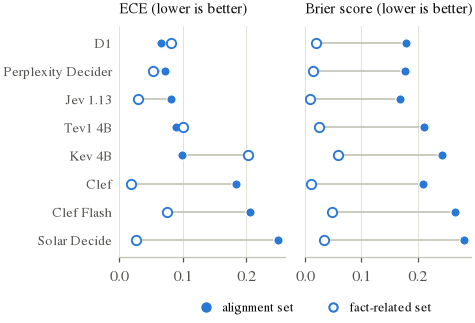

In [ ]:
# Appendix I: the two calibration measures side by side, one row per TDM, both datasets (uses cal and cal_f above)
order_c = sorted(F.MODELS, key=lambda m: cal[m, "alignment"]["ece"], reverse=True)          # best calibrated at the top
fig, (e_ax, b_ax) = plt.subplots(1, 2, figsize=(F.COLUMN, 2.0), sharey=True, gridspec_kw={"wspace": 0.12})
for ax_, key, title in [(e_ax, "ece", "ECE"), (b_ax, "brier", "Brier score")]:
    for i, m in enumerate(order_c):
        a, f = cal[m, "alignment"][key], cal_f[m][key]
        ax_.plot([min(a, f), max(a, f)], [i, i], color=F.AXIS, lw=0.8, zorder=1)
        ax_.scatter([a], [i], s=20, color=F.TYPED, edgecolor="white", lw=0.6, zorder=3)
        ax_.scatter([f], [i], s=20, facecolor="white", edgecolor=F.TYPED, lw=0.9, zorder=3)
    ax_.set_title(f"{title} (lower is better)", loc="left", fontsize=7)
    ax_.grid(axis="x", color=F.GRID, lw=0.5); ax_.set_axisbelow(True)
    ax_.spines["left"].set_visible(False); ax_.tick_params(axis="y", length=0)
    ax_.set_xlim(0, None)
e_ax.set_yticks(range(len(order_c))); e_ax.set_yticklabels([F.MODEL_NAMES[m] for m in order_c], fontsize=6.6)
e_ax.set_ylim(-0.6, len(order_c) - 0.4)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=F.TYPED, ms=4, label="alignment set"),
                    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=F.TYPED, ms=4, label="fact-related set")],
           loc="upper center", bbox_to_anchor=(0.55, 0.0), ncol=2, fontsize=6.3, frameon=False, handletextpad=0.2)
F.save(fig, "calibration_summary")
pd.DataFrame({m: {"ece_al": cal[m, "alignment"]["ece"], "ece_fa": cal_f[m]["ece"], "brier_al": cal[m, "alignment"]["brier"], "brier_fa": cal_f[m]["brier"]}
              for m in order_c}).T.round(3)

## Appendix table: time and cost per model and format, and the LLM sample

In [ ]:
tc = pd.read_csv(F.TABLES / "time_and_cost.csv")
lines = []
for m in F.MODELS:
    for i, f in enumerate(["calm", "native", "decomposed"]):
        r = tc[(tc.model == m) & (tc.format == f)].iloc[0]
        lines.append(f"{F.MODEL_NAMES[m] if i == 0 else ''} & {FMT[f]} & {r.wall_min:.1f} & {str(r.concurrency).split('/')[0]} & {r.usd:.2f} & {r.usd_per_1000:.3f} & {r.median_latency_s:.2f} \\\\")
lines.append("\\midrule")
llm_tc = pd.read_csv(F.TABLES / "llm_time_and_cost.csv").set_index("judge")
for name in F.LLMS:
    c = llm_tc.loc[name]
    lines.append(f"{name} & CALM prompt & -- & {F.LLM_PARALLEL[name]} & {c.usd:.2f} & {c.usd_per_1000:.3f} & {c.median_latency_s:.2f} \\\\")
F.write_tex("appendix_cost", r"""\begin{table*}[t]
\centering
\footnotesize
\begin{tabular}{@{}ll ccccc@{}}
\toprule
Judge & Format & Minutes & Parallel requests & US\$ & US\$ per 1,000 & Latency (s) \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Time and cost of the full design (15,195 requests per model and format). Minutes: wall-clock time of all sending passes. Parallel requests: requests in flight in the main pass. Latency: median seconds per request, the time of the answered attempt without retries, with the stated number of parallel requests. The LLM judges answer CALM's prompt as text over the same design. Their cost is the cost OpenRouter reported in October 2026 (Claude Sonnet 5.5 at Anthropic's list price), and their minutes are not comparable, since their runs were interrupted by credit limits.}
\label{tab:cost}
\end{table*}
""")
tc[["model", "format", "wall_min", "usd", "usd_per_1000", "median_latency_s"]].round(3)

,model,format,wall_min,usd,usd_per_1000,median_latency_s
0,jev-1.13,calm,2.248,0.677,0.045,0.252
1,jev-1.13,native,3.547,0.683,0.045,0.343
2,jev-1.13,decomposed,4.572,1.227,0.081,0.492
3,kev-4b,calm,16.457,0.494,0.033,1.901
4,kev-4b,native,20.330,0.479,0.032,1.862
5,kev-4b,decomposed,23.313,0.892,0.059,2.763
6,tev1-4b,calm,10.522,0.547,0.036,0.559
7,tev1-4b,native,4.700,0.530,0.035,0.532
8,tev1-4b,decomposed,10.755,3.117,0.205,1.249
9,solar-decide,calm,46.597,0.836,0.055,2.866


## Appendix tables: mixed models, item agreement, criteria and ensemble

The mixed models are fitted in R (`R/flips.R`, `R/shifts.R`, run by `05_exploratory`), which write their estimates
to `data/exploratory/*.csv`.

In [ ]:
EXP = F.CODE / "data" / "exploratory"
odds = pd.read_csv(EXP / "flips_odds.csv")
NICE = {"margin10": "Margin of the original, per 0.1", "orig_correct": "Judge right on the original",
        "log_len_ratio": "Log length ratio, $R_1$ to $R_2$", "formatnative": "Native format (vs CALM)",
        "formatdecomposed": "Decomposed format (vs CALM)"}
def term_name(t):
    if t in NICE: return NICE[t]
    if t.startswith("bias"): return "Test: " + F.TEST_NAMES.get(t[4:], t[4:])
    if t.startswith("model"): return "Model: " + F.MODEL_NAMES.get(t[5:], t[5:])
    if t.startswith("source"): return "Source: " + t[6:]
    return t
lines = []
for r in odds[(odds.term != "(Intercept)") & ~odds.term.str.startswith("format")].itertuples():   # format terms: Appendix K
    lines.append(f"{term_name(r.term)} & {r.odds_ratio:.2f} & [{r.lo:.2f}, {r.hi:.2f}] \\\\")
info = pd.read_csv(EXP / "flips_info.csv").iloc[0]
F.write_tex("appendix_mixed", r"""\begin{table}[t]
\centering
\footnotesize
\begin{tabular}{@{}l cc@{}}
\toprule
Term & Odds ratio & 95\% CI \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Logistic mixed model of a flipped verdict, CALM format, with a random intercept per item (""" +
f"{int(info['n']):,} prompts, {int(info['items'])} items, item variance {info['item_variance']:.2f} on the logit scale, intraclass correlation {info['icc']:.2f}" +
r"""). References: the neutral note, \jev{} and Emerton-DPO. ScienceQA has no term of its own. The tests of the fact-related set use only its three sources, so the effect of ScienceQA is contained in the terms of sentiment and verbosity, and GSM8K and MATH are relative to ScienceQA.}
\label{tab:mixed}
\end{table}
""")
var_ = pd.read_csv(EXP / "variance_shift.csv")
GRP = {"bias": "Test", "model": "Model", "format": "Format", "source": "Source", "item": "Item", "Residual": "Residual"}
def grp_name(g):
    return " $\\times$ ".join(GRP.get(x, x) for x in g.split(":"))
pv = var_.pivot(index="grp", columns="outcome", values="share")
pv = pv.loc[pv["signed"].sort_values(ascending=False).index]
lines = [f"{grp_name(g)} & {100 * r.signed:.1f} & {100 * r['size']:.1f} \\\\" for g, r in pv.iterrows()]
F.write_tex("appendix_variance", r"""\begin{table}[t]
\centering
\footnotesize
\begin{tabular}{@{}l cc@{}}
\toprule
Variance component & Shift (\%) & Size of shift (\%) \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Share of the variance of the shift \pshift{} and of its size $|\pshift|$ by crossed random effects, all formats, without fallacy oversight. The residual holds the variation between the versions and formats of a prompt that no component captures.}
\label{tab:variance}
\end{table}
""")
pv

outcome,signed,size
grp,,
Residual,0.567,0.574
bias,0.252,0.138
item:bias,0.080,0.053
bias:model,0.060,0.073
item:model,0.020,0.090
model,0.014,0.005
bias:format,0.004,0.004
model:format,0.001,0.006
source,0.001,0.006


In [ ]:
d_long = pd.read_csv(EXP / "long.csv.gz")
d_long = d_long[(d_long.format == "calm") & (d_long.bias != "fallacy")]
from itertools import combinations
items = []
for b, g in d_long.groupby("bias"):
    w = g.groupby(["item", "model"])["shift"].mean().unstack()
    wf = g.groupby(["item", "model"])["flip"].mean().unstack()
    items.append({"test": b, "shift": np.nanmean([w[a].corr(w[c], method="spearman") for a, c in combinations(w.columns, 2)]),
                  "flip": np.nanmean([wf[a].corr(wf[c], method="spearman") for a, c in combinations(wf.columns, 2)])})
items = pd.DataFrame(items).sort_values("shift", ascending=False)
lines = [f"{F.TEST_NAMES[r.test]} & {r.shift:.2f} & {r.flip:.2f} \\\\" for r in items.itertuples()]
F.write_tex("appendix_items", r"""\begin{table}[t]
\centering
\footnotesize
\begin{tabular}{@{}l cc@{}}
\toprule
Test & Shift & Flip \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Agreement between models on which items move: mean Spearman correlation, over all pairs of models, of the per-item mean shift and flip rate, CALM format.}
\label{tab:items}
\end{table}
""")
items.round(2)

.venv/lib/python3.13/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,test,shift,flip
8,sentiment,0.57,0.51
0,authority,0.41,0.21
9,verbosity,0.35,0.13
1,"authority, better response",0.35,0.21
2,bandwagon,0.29,0.13
5,diversity,0.28,0.13
10,"verbosity, better response",0.27,0.18
6,"diversity, neutral note",0.27,0.09
7,position,0.17,0.18
3,compassion,0.14,0.05


In [ ]:
# Do TDMs and LLM judges flip on the same prompts? (09_llm_analysis, section 14)
ov = pd.read_csv(F.TABLES / "llm_item_overlap.csv")
sm = pd.read_csv(F.TABLES / "llm_item_overlap_summary.csv").set_index("pair")
KINDS = ["typed - typed", "LLM 2026 - LLM 2026", "typed - LLM 2026"]
# correlation of the prompt effects of TDMs and LLM judges in the logistic mixed model of R/item_overlap.R
mm = pd.read_csv(F.CODE / "data" / "exploratory" / "item_overlap_model.csv")
r_test = {m.removeprefix("test: "): r for m, r in zip(mm.model, mm["cor"]) if m.startswith("test: ")}
r_all = mm.loc[mm.model == "TDM - LLM, all tests", "cor"].item()
w = ov.pivot(index="test", columns="pair")
order = w[("if the other flips", "typed - LLM 2026")].sort_values(ascending=False).index
cell = lambda y, n: f"{100 * y:.0f} / {100 * n:.0f}"
lines = [F.TEST_NAMES[t] + " & " + " & ".join(cell(w.loc[t, ("if the other flips", k)], w.loc[t, ("if the other stays", k)])
                                         for k in KINDS) + f" & {r_test[t]:.2f}" + r" \\" for t in order]
lines.append(r"\midrule")
lines.append("Mean & " + " & ".join(cell(sm.loc[k, "if the other flips"], sm.loc[k, "if the other stays"]) for k in KINDS)
             + f" & {r_all:.2f}" + r" \\")
ci = lambda k: f"{100 * sm.loc[k, 'lo']:.0f} to {100 * sm.loc[k, 'hi']:.0f}"
F.write_tex("appendix_item_overlap", r"""\begin{table}[t]
\centering
\footnotesize
\setlength{\tabcolsep}{2.5pt}
\begin{tabular}{@{}l cccc@{}}
\toprule
Test & \makecell{Two\\TDMs} & \makecell{Two LLM\\judges} & \makecell{TDM and\\LLM judge} & $r$ \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Do two judges flip on the same prompts? For a pair of judges, the share of prompts (\%) on which the verdict
of the second flips, among those on which the verdict of the first flips / does not flip, averaged over the pairs of
eight TDMs (CALM format), of the five 2026 LLM judges, and of a TDM and a 2026 LLM judge (both ways round).
95\% bootstrap intervals over items for the mean when the first flips: """ + f"{ci(KINDS[0])}, {ci(KINDS[1])} and {ci(KINDS[2])}" + r""". Fallacy oversight
is left out, since there a flip is the correct reaction. $r$: correlation of the prompt effects of the TDMs and the
2026 LLM judges in a logistic mixed model of the test, and of all tests in the last row (Appendix~\ref{app:models-llm}). A value of
1.00 is its upper limit.}
\label{tab:item-overlap}
\end{table}
""")
sm.round(3)

,if the other flips,lo,hi,if the other stays,lo,hi,"Spearman, item flip rates"
pair,,,,,,,
typed - typed,0.264,0.253,0.275,0.096,0.092,0.100,0.169
LLM 2026 - LLM 2026,0.300,0.284,0.316,0.097,0.092,0.103,0.225
typed - LLM 2026,0.265,0.254,0.277,0.103,0.098,0.107,0.168


In [ ]:
# Do the LLM judges name the cue in their explanation? (09_llm_analysis, section 17)
cm_all = pd.read_csv(F.TABLES / "llm_cue_mentions.csv")
cm = cm_all.query("generation == 2026").set_index("test"); co = cm_all.query("generation == 2024").set_index("test")
ORDER = ["authority", "authority, better response", "sentiment", "verbosity", "verbosity, better response",
         "distraction", "diversity", "diversity, neutral note", "bandwagon"]
pc = lambda x: f"{100 * x:.0f}"
lines = [f"{F.TEST_NAMES[t]} & {pc(cm.loc[t, 'original'])} & {pc(cm.loc[t, 'perturbed'])} & {pc(cm.loc[t, 'flipped'])} & "
         f"{pc(cm.loc[t, 'unchanged'])} & {pc(co.loc[t, 'original'])} & {pc(co.loc[t, 'perturbed'])} \\\\" for t in ORDER]
F.write_tex("appendix_cue_mentions", r"""\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}l cccc cc@{}}
\toprule
 & \multicolumn{4}{c}{LLM judges 2026} & \multicolumn{2}{c}{LLM judges 2024} \\
\cmidrule(lr){2-5} \cmidrule(l){6-7}
Test & Original & Cue & Flipped & Unchanged & Original & Cue \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{How often the explanations of the LLM judges name the cue of a test (\%). Original: explanations on the
original prompts, where the cue is absent, so the words occur by chance. Cue: explanations on the prompts with the cue.
For the 2026 judges, the prompts with the cue are also split by whether the verdict flipped or stayed the same.
Table~\ref{tab:cue-words} lists the words.}
\label{tab:cue-mentions}
\end{table}
""")
pd.concat([cm, co], keys=["2026", "2024"]).round(2)

generation  original  perturbed  flipped  \
     test                                                                   
2026 authority                         2026      0.25       0.96     0.99   
     authority, better response        2026      0.25       0.96     1.00   
     bandwagon                         2026      0.05       0.27     0.25   
     distraction                       2026      0.04       0.52     0.60   
     diversity                         2026      0.22       0.46     0.50   
     diversity, neutral note           2026      0.22       0.28     0.27   
     sentiment                         2026      0.52       0.83     0.87   
     verbosity                         2026      0.49       0.90     0.89   
     verbosity, better response        2026      0.49       0.64     0.80   
2024 authority                         2024      0.08       0.66     0.83   
     authority, better response        2024      0.08       0.65     0.82   
     bandwagon                         2024      0.02       0.04     0.06   
     distraction                       2024      0.03       0.19     0.22   
     diversity                         2024      0.10       0.14     0.11   
     diversity, neutral note           2024      0.10       0.14     0.11   
     sentiment                         2024      0.28       0.62     0.74   
     verbosity                         2024      0.42       0.87     0.61   
     verbosity, better response        2024      0.42       0.21     0.40   

                                 unchanged  
     test                                   
2026 authority                        0.95  
     authority, better response       0.94  
     bandwagon                        0.27  
     distraction                      0.51  
     diversity                        0.46  
     diversity, neutral note          0.28  
     sentiment                        0.82  
     verbosity                        0.90  
     verbosity, better response       0.61  
2024 authority                        0.62  
     authority, better response       0.62  
     bandwagon                        0.04  
     distraction                      0.19  
     diversity                        0.15  
     diversity, neutral note          0.14  
     sentiment                        0.58  
     verbosity                        0.91  
     verbosity, better response       0.19

In [ ]:
# Our two 2024 judges against the numbers CALM reports for them (09_llm_analysis, section 8)
vc = pd.read_csv(F.TABLES / "llm_vs_calm.csv")
w = vc.pivot(index="bias", columns="judge", values=["ours", "CALM"])
ORDER = ["verbosity", "fallacy", "sentiment", "CR fact", "position", "compassion", "bandwagon", "authority",
         "distraction", "diversity", "CR alignment"]
LAB = dict(F.TEST_NAMES, **{"fallacy": "Fallacy oversight", "CR fact": "\\CR{}, fact-related",
                            "CR alignment": "\\CR{}, alignment"})
lines = []
for b in ORDER:
    if b == "position":
        lines.append(r"\midrule")
    lines.append(LAB[b] + " & " + " & ".join(f"{w.loc[b, (s, j)]:.2f}" for j in ["ChatGPT", "GPT-4o"] for s in ["ours", "CALM"]) + r" \\")
F.write_tex("appendix_vs_calm", r"""\begin{table}[t]
\centering
\footnotesize
\begin{tabular}{@{}l cc cc@{}}
\toprule
 & \multicolumn{2}{c}{ChatGPT} & \multicolumn{2}{c}{GPT-4o} \\
\cmidrule(lr){2-3} \cmidrule(l){4-5}
Test & Ours & CALM & Ours & CALM \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Robustness rate of the two 2024 LLM judges in our runs and as reported in Table~4 of the original CALM
study \citep{ye2025justice}.}
\label{tab:vs-calm}
\end{table}
""")
w.round(3)

ours           CALM       
judge        ChatGPT GPT-4o ChatGPT GPT-4o
bias                                      
CR alignment   0.959  0.954   0.906  0.925
CR fact        0.970  0.985   0.998  0.998
authority      0.836  0.838   0.662  0.787
bandwagon      0.813  0.924   0.688  0.791
compassion     0.859  0.891   0.862  0.868
distraction    0.920  0.902   0.713  0.790
diversity      0.916  0.928   0.679  0.814
fallacy        0.615  0.974   0.917  0.984
position       0.587  0.745   0.566  0.776
sentiment      0.807  0.689   0.804  0.699
verbosity      0.810  0.968   0.900  0.977

## Figure: ensemble of all eight models (main text)

Per test, the range and median of the excess of the single models, and the excess of the majority vote of all eight.

saved


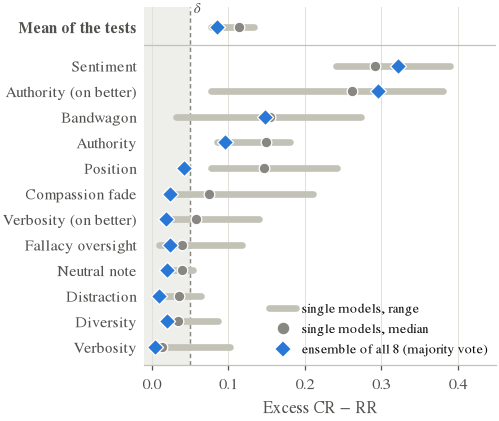

In [ ]:
from judgebias import ensembles as E
M = E.Matrix("calm")
J = E.judges(M, pd.read_csv(F.TABLES / "time_and_cost.csv").query("format == 'calm'").rename(columns={"model": "judge"}))
single = J[J.kind == "single"]
vote = J[J.judge == "all 8, vote"].iloc[0]
mean_ = J[J.judge == "all 8, mean"].iloc[0]
TESTS = [t for t in single.columns if t in F.TEST_NAMES]
order = single[TESTS].median().sort_values().index.tolist()
rows = order + ["mean excess"]
LABEL = dict(F.TEST_NAMES, **{"mean excess": "Mean of the tests"})
y = {t: i for i, t in enumerate(order)}; y["mean excess"] = len(order) + 0.5
fig, ax = plt.subplots(figsize=(F.COLUMN, 3.1))
ax.axvspan(-0.01, F.DELTA, color="#eeeeea", lw=0, zorder=0)
ax.axvline(F.DELTA, color=F.MUTED, lw=0.7, ls=(0, (3, 2)), zorder=1)
for t in rows:
    v = single[t]
    ax.plot([v.min(), v.max()], [y[t]] * 2, color=F.AXIS, lw=3.2, solid_capstyle="round", zorder=2)
    ax.scatter([v.median()], [y[t]], s=26, color=F.MUTED, edgecolor="white", lw=0.6, zorder=3)
    ax.scatter([vote[t]], [y[t]], s=30, marker="D", color=F.TYPED, edgecolor="white", lw=0.6, zorder=4)
ax.axhline(len(order) - 0.2, color=F.AXIS, lw=0.6)
ax.set_yticks([y[t] for t in rows]); ax.set_yticklabels([LABEL[t] for t in rows])
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.spines["left"].set_visible(False)
ax.set_xlim(-0.01, 0.45); ax.set_ylim(-0.7, y["mean excess"] + 0.8)
ax.set_xlabel("Excess CR $-$ RR")
ax.grid(axis="x", color=F.GRID, lw=0.5); ax.set_axisbelow(True)
ax.text(F.DELTA + 0.005, y["mean excess"] + 0.55, r"$\delta$", color=F.INK2, fontsize=7)
ax.legend(handles=[Line2D([], [], color=F.AXIS, lw=3.2, label="single models, range"),
                   Line2D([], [], marker="o", ls="", color=F.MUTED, ms=4.5, label="single models, median"),
                   Line2D([], [], marker="D", ls="", color=F.TYPED, ms=4.2, label="ensemble of all 8 (majority vote)")],
          loc="lower right", fontsize=6.5, handletextpad=0.4, borderaxespad=0.2)
F.save(fig, "ensemble"); print("saved")

In [ ]:
## Appendix tables: ensembles and one model in both orders

In [ ]:
# appendix tables: every single model and every combination of all 8, and one model in both orders
cols = [("mean excess", "Mean", 3), ("position", "Pos.", 3), ("compassion", "Com.", 3), ("sentiment", "Sen.", 3),
        ("bandwagon", "Ban.", 3), ("authority, better response", "Aut.\\ (b.)", 3), ("fallacy", "Fal.", 3),
        ("accuracy", "Acc.", 2), ("usd_per_1000", "US\\$/1k", 3), ("latency_s", "s", 2)]
NAME = dict(F.MODEL_NAMES, **{f"all 8, {h}": f"All 8, {h}" for h in E.COMBINERS})
lines = []
for k, r in J.iterrows():
    if k == len(F.MODELS):
        lines.append("\\midrule")
    lines.append(NAME[r.judge] + " & " + " & ".join(f"{r[c]:.{d}f}" for c, _, d in cols) + " \\\\")
F.write_tex("appendix_ensemble", r"""\begin{table*}[t]
\centering
\footnotesize
\begin{tabular}{@{}l ccccccc c cc@{}}
\toprule
 & \multicolumn{7}{c}{Excess} & & & \\
\cmidrule(lr){2-8}
Judge & """ + " & ".join(h for _, h, _ in cols) + r""" \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Single typed models and four ways of combining all eight, CALM format, on the requests that all models answered. Mean: mean excess over the twelve tests. Fal.: fallacy oversight, the share of overlooked flaws beyond chance, $\RR + \CR - 1$. Acc.: accuracy on the original alignment prompts. Cost of an ensemble: the sum of its models' costs. Latency: the slowest model's median, when all models are asked in parallel.}
\label{tab:ensemble}
\end{table*}
""")
B = E.both_orders().set_index("model").loc[F.MODELS]
lines = [f"{F.MODEL_NAMES[m]} & {r.accuracy_one_order:.3f} & {r.accuracy_both_orders:.3f} & ${100 * r.change:+.1f}$ [${100 * r.change_lo:+.1f}$, ${100 * r.change_hi:+.1f}$] & {r.orders_agree:.2f} \\\\"
         for m, r in B.iterrows()]
F.write_tex("appendix_both_orders", r"""\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2.5pt}
\begin{tabular}{@{}l cccc@{}}
\toprule
Model & One & Both & Change & Agree \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Accuracy on the 439 items of the position test when a model judges the pair in one order (One), and when the probabilities of both orders are averaged (Both), which removes position bias by construction. Change: Both minus One, in percentage points, with a 95\% bootstrap interval over items. Agree: share of items with the same verdict in both orders. A 50/50 answer has no verdict and is left out.}
\label{tab:both-orders}
\end{table}
""")
S_ = E.subsets(M)
display(J.round(3)); display(B.round(3))
S_.groupby("k").excess_B.agg(["median", "min"]).round(3).T

,judge,kind,authority,"authority, better response",bandwagon,compassion,distraction,diversity,"diversity, neutral note",fallacy,position,sentiment,verbosity,"verbosity, better response",mean excess,accuracy,usd_per_1000,latency_s
0,jev-1.13,single,0.123,0.291,0.200,0.021,0.054,0.023,0.031,0.020,0.085,0.366,0.000,0.094,0.109,0.777,0.045,0.252
1,kev-4b,single,0.151,0.224,0.191,0.150,0.065,0.086,0.054,0.010,0.191,0.389,0.004,0.090,0.134,0.647,0.033,1.901
2,tev1-4b,single,0.147,0.233,0.045,0.210,0.047,0.060,0.051,0.071,0.243,0.254,0.014,0.028,0.117,0.656,0.036,0.559
3,solar-decide,single,0.085,0.120,0.032,0.078,0.023,0.022,0.029,0.058,0.155,0.241,0.056,0.032,0.078,0.667,0.055,2.866
4,d1,single,0.181,0.297,0.067,0.080,0.030,0.045,0.047,0.036,0.123,0.346,0.014,0.140,0.117,0.752,0.031,0.378
5,pplx-decider-v1.1-27b,single,0.163,0.380,0.260,0.043,0.019,0.017,0.018,0.044,0.077,0.293,0.006,0.024,0.112,0.749,0.017,0.376
6,clef,single,0.167,0.342,0.273,0.052,0.010,0.017,0.017,0.032,0.139,0.290,0.012,0.060,0.118,0.752,0.205,0.532
7,clef-flash,single,0.118,0.078,0.119,0.071,0.042,0.050,0.052,0.118,0.194,0.272,0.102,0.056,0.106,0.649,0.077,0.471
8,"all 8, mean",ensemble,0.125,0.276,0.159,0.046,0.026,0.029,0.031,0.032,0.082,0.323,0.008,0.022,0.096,0.722,0.498,2.866
9,"all 8, median",ensemble,0.111,0.313,0.186,0.071,0.031,0.037,0.042,0.028,0.071,0.333,0.006,0.026,0.105,0.740,0.498,2.866


,items,accuracy_one_order,accuracy_both_orders,change,change_lo,change_hi,orders_agree
model,,,,,,,
jev-1.13,439,0.777,0.789,0.012,-0.006,0.032,0.897
kev-4b,439,0.647,0.645,-0.002,-0.030,0.025,0.809
tev1-4b,439,0.656,0.695,0.038,0.006,0.072,0.755
solar-decide,439,0.667,0.690,0.024,-0.006,0.054,0.753
d1,439,0.752,0.773,0.022,-0.003,0.047,0.873
pplx-decider-v1.1-27b,439,0.749,0.752,0.002,-0.016,0.021,0.923
clef,439,0.752,0.770,0.018,-0.007,0.046,0.861
clef-flash,439,0.649,0.672,0.023,-0.005,0.050,0.806


k,1,2,3,4,5,6,7,8
median,0.118,0.112,0.101,0.102,0.099,0.101,0.099,0.097
min,0.066,0.060,0.060,0.062,0.075,0.081,0.091,0.097


## Appendix tables: excess with intervals, direction of the cues, settings of the LLM judges (review round 2)

In [ ]:
# Appendix tables asked for in review round 2: the excess of every judge with its interval (so that Figure 2 can be
# checked), the change in the share of verdicts for the cued response, and the settings of the LLM judges.
def ex_cell(r):
    s = f"{100 * r.excess:.0f} [{100 * r.excess_lo:.0f}, {100 * r.excess_hi:.0f}]"
    if F.classify(r.excess_lo, r.excess_hi) == "bias":
        s = f"\\textbf{{{s}}}"
    if r.bias != "fallacy" and not r.significant:
        s += "$^{\\circ}$"
    return s
order_t = calm.groupby("bias").excess.median().sort_values(ascending=False).index.tolist()
def excess_table(judges, names, label, caption):
    head = " & ".join(names[j] for j in judges)
    lines = []
    for b in order_t:
        g = both[both.bias == b].set_index("model")
        lines.append(test_label(b) + " & " + " & ".join(ex_cell(g.loc[j]) if j in g.index else "--" for j in judges) + " \\\\")
    return (r"""\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}l """ + "c" * len(judges) + r"""@{}}
\toprule
Test & """ + head + r""" \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{""" + caption + r"""}
\label{""" + label + r"""}
\end{table*}
""")
short_t = {"jev-1.13": "Jev", "kev-4b": "Kev", "tev1-4b": "Tev1", "solar-decide": "Solar", "d1": "D1",
           "pplx-decider-v1.1-27b": "Perplexity", "clef": "Clef", "clef-flash": "Clef Flash"}
cap = (r"Excess in changed verdicts per 100 beyond chance, with its 95\% bootstrap interval over items, {who}. "
       r"\textbf{{Bold}}: a bias at $\delta = 0.05$. $^{{\circ}}$: not significant in the permutation test after the "
       r"Benjamini--Hochberg correction (fallacy oversight has no permutation test). $^\dagger$Our additions. "
       r"$^\ast$For fallacy oversight, $\RR + \CR - 1$.")
F.write_tex("appendix_excess_typed", excess_table(F.MODELS, short_t, "tab:excess-typed",
            cap.format(who="TDMs in the CALM format")))
F.write_tex("appendix_excess_llm", excess_table(F.LLMS, F.LLM_SHORT, "tab:excess-llm",
            cap.format(who="LLM judges on the same prompts")))

# change in the share of verdicts for the response that carries the cue (verdicts only, all judges)
dirn = pd.read_csv(F.TABLES / "llm_direction.csv")
PULLS = [("position", "R1", "Pos.\\ (b.)"), ("position", "R2", "Pos.\\ (w.)"),
         ("verbosity", "R2", "Ver."), ("verbosity, better response", "R1", "Ver.\\ (b.)"),
         ("bandwagon", "R2", "Ban."), ("compassion", "R2", "Com."), ("authority", "R2", "Aut."),
         ("authority, better response", "R1", "Aut.\\ (b.)"), ("sentiment", "R1", "Sen.\\ (b.)"),
         ("sentiment", "R2", "Sen.\\ (w.)")]
pv = dirn.set_index(["judge", "bias", "target"]).pull
def prow(j):
    return [100 * pv.loc[(j, b, t)] if (j, b, t) in pv.index else np.nan for b, t, _ in PULLS]
typed_names = [F.MODEL_NAMES[m] for m in F.MODELS]
fmt_ = lambda x: "--" if np.isnan(x) else f"${x:+.0f}$"
lines = [f"\\multicolumn{{11}}{{@{{}}l}}{{\\emph{{TDMs, CALM format}}}} \\\\"]
lines += [j + " & " + " & ".join(fmt_(x) for x in prow(j)) + " \\\\" for j in typed_names]
lines += ["\\midrule", f"\\multicolumn{{11}}{{@{{}}l}}{{\\emph{{LLM judges}}}} \\\\"]
lines += [j + " & " + " & ".join(fmt_(x) for x in prow(j)) + " \\\\" for j in F.LLMS]
lines += ["\\midrule", "TDMs, median & " + " & ".join(fmt_(x) for x in np.nanmedian([prow(j) for j in typed_names], axis=0)) + " \\\\",
          "LLM judges 2026, median & " + " & ".join(fmt_(x) for x in np.median([prow(j) for j in F.LLMS_2026], axis=0)) + " \\\\"]
F.write_tex("appendix_pulls", r"""\begin{table*}[t]
\centering
\footnotesize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}l cccccccccc@{}}
\toprule
Judge & """ + " & ".join(h for _, _, h in PULLS) + r""" \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Change in the share of verdicts for the response that carries the cue, after minus before the perturbation,
in percentage points. Positive: the cue pulls verdicts towards its response. Pos.: position, with the better (b.) or the
worse (w.) response moved to the second place. Sen.: sentiment, with the tone on the better (b.) or the worse (w.)
response. Other abbreviations as in Table~\ref{tab:main}. Under bandwagon and compassion fade, the cue favours the worse
response.}
\label{tab:pulls}
\end{table*}
""")

# settings of the LLM judges
comp = pd.read_csv(F.TABLES / "llm_completeness.csv").set_index("judge")
from judgebias import llm_judges as Lj
ROUTE = {j: (f"\\texttt{{{Lj.file_model(j)}}}", "Anthropic API" if j in Lj.BATCH_MODELS else "OpenRouter") for j in F.LLMS}
PAR = F.LLM_PARALLEL
lines = []
for j in F.LLMS:
    r = comp.loc[j]
    lines.append(" & ".join([j, ROUTE[j][0], ROUTE[j][1], "0" if r["temperature 0"] else "default",
                             r["reasoning"].replace(" (mandatory)", ", required"),
                             f"{100 * r['share with verdict']:.1f}"]) + " \\\\")
F.write_tex("appendix_llm_settings", r"""\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}ll l c l r@{}}
\toprule
Judge & Model as returned & Route & Temperature & Reasoning & Verdicts (\%) \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Settings of the LLM judges. Every judge received all 15,195 requests of the design. Verdicts: share of
requests whose reply names a verdict, \texttt{[[A]]} or \texttt{[[B]]}. The rest are refusals, empty replies,
replies without a verdict and failed requests (Appendix~\ref{app:judge-prompt}).}
\label{tab:llm-settings}
\end{table*}
""")
print(open(F.TEX / "appendix_llm_settings.tex").read())


\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}ll l c l r@{}}
\toprule
Judge & Model as returned & Route & Temperature & Reasoning & Verdicts (\%) \\
\midrule
GPT-3.5 Turbo & \texttt{openai/gpt-3.5-turbo} & OpenRouter & 0 & off & 99.4 \\
GPT-4o & \texttt{openai/gpt-4o-2024-05-13} & OpenRouter & 0 & off & 99.9 \\
GPT-6.1 Sol & \texttt{openai/gpt-6.1-sol} & OpenRouter & default & low, required & 100.0 \\
Claude Sonnet 5.5 & \texttt{claude-sonnet-5-5} & Anthropic API & default & off & 100.0 \\
Gemini 3.8 Flash & \texttt{google/gemini-3.8-flash} & OpenRouter & 0 & low, required & 99.6 \\
Qwen3.8-27B & \texttt{qwen/qwen3.8-27b} & OpenRouter & 0 & off & 99.9 \\
Claude Haiku 5.5 & \texttt{anthropic/claude-haiku-5.5} & OpenRouter & default & off & 98.1 \\
\bottomrule
\end{tabular}
\caption{Settings of the LLM judges. Every judge received all 15,195 requests of the design. Verdicts: share of
requests whose reply names a verdict, \texttt{[[A]]} or \texttt

In [ ]:
# Details of the typed decision models (review round 3), the counterpart of Table tab:llm-settings: the version each
# model returns with its answers, the base model its maker names, and the share of requests with a verdict per format.
FULL = {m.split("/")[-1].replace("-experimental", ""): m for m in run.MODELS}
BASE = {"jev-1.13": "not disclosed", "kev-4b": "Qwen", "tev1-4b": "Qwen", "solar-decide": "Solar Mini 4",
        "d1": "not disclosed", "pplx-decider-v1.1-27b": "Qwen3.8-27B", "clef": "Qwen3.8-27B", "clef-flash": "Qwen"}
FORMATS = ["calm", "native", "decomposed"]
def has_verdict(r):
    return bool(r["ok"]) and r["choice"] is not None and abs(r["p_A"] - 0.5) >= metrics.TIE
lines, details = [], []
for m in F.MODELS:
    recs = {f: run.load_records(FULL[m], f) for f in FORMATS}
    snaps = {r["snapshot"] for f in FORMATS for r in recs[f] if r["ok"]}
    assert len(snaps) == 1, (m, snaps)                       # one version for all answers of a model
    share = {f: 100 * np.mean([has_verdict(r) for r in recs[f]]) for f in FORMATS}
    details.append({"model": m, "version": snaps.pop(), "base": BASE[m], **{f: round(share[f], 2) for f in FORMATS},
                    "requests": [len(recs[f]) for f in FORMATS]})
    d = details[-1]
    lines.append(" & ".join([F.MODEL_NAMES[m], f"\\texttt{{{d['version']}}}", d["base"]]
                            + [f"{share[f]:.1f}" for f in FORMATS]) + " \\\\")
F.write_tex("appendix_typed_settings", r"""\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{3pt}
\begin{tabular}{@{}ll l ccc@{}}
\toprule
 & & & \multicolumn{3}{c}{Verdicts (\%)} \\
\cmidrule(l){4-6}
Model & Version as returned & Built on & CALM & native & decomposed \\
\midrule
""" + "\n".join(lines) + r"""
\bottomrule
\end{tabular}
\caption{Details of the TDMs. Every model received all 15,195 requests of the design in each of the three
formats through OpenRouter's Decisions API. Verdicts: share of requests with a verdict, that is, without a 50/50
answer or a failed request (Appendix~\ref{app:formats}).}
\label{tab:typed-settings}
\end{table*}
""")
pd.DataFrame(details)

,model,version,base,calm,native,decomposed,requests
0,jev-1.13,typesafe/jev-1.13-20260917,not disclosed,99.57,99.54,99.89,"[15195, 15195, 15195]"
1,kev-4b,jaredpalmer/kev-4b-20260924,Qwen,99.99,99.97,99.99,"[15195, 15195, 15195]"
2,tev1-4b,togethercomputer/tev1-4b-experimental-20260923,Qwen,97.27,97.98,99.78,"[15195, 15195, 15195]"
3,solar-decide,upstage/solar-decide-20260928,Solar Mini 4,99.23,99.23,99.99,"[15195, 15195, 15195]"
4,d1,liquid/d1-20260930,not disclosed,98.35,98.27,99.92,"[15195, 15195, 15195]"
5,pplx-decider-v1.1-27b,perplexity/pplx-decider-v1.1-27b-20261006,Qwen3.8-27B,100.00,100.00,100.00,"[15195, 15195, 15195]"
6,clef,cloudflare/clef,Qwen3.8-27B,100.00,99.99,100.00,"[15195, 15195, 15195]"
7,clef-flash,cloudflare/clef-flash,Qwen,100.00,100.00,100.00,"[15195, 15195, 15195]"
